In [1]:
# RFA with single sample per met to prevents repeated sampling from inflating site counts
# 2C) Merge chunk TSVs into short_rawdata...tsv and long_rawdata...tsv
# Make sure that bins match (Sort each TSV using awk->Verify now bins match AND order matches) (Step 3)
import os, glob
import pandas as pd
import numpy as np
import bisect
import os
import py2bit
import deeptools
import statsmodels.api as sm

INDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb"
OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb"
os.makedirs(OUTDIR, exist_ok=True)

def merge_sorted_chunks(mode: str):
    files = sorted(glob.glob(os.path.join(INDIR, f"{mode}.bamchunk_*.sorted.tsv")))
    if not files:
        raise FileNotFoundError(f"No files found for {mode} in {INDIR}")

    print(f"[{mode}] Found {len(files)} files")

    # Load first file (keeps chrom/start/end + first set of samples)
    out = pd.read_csv(files[0], sep="\t")
    coord = out[["chrom", "start", "end"]].copy()

    seen = set(out.columns[3:])  # sample columns
    print(f"[{mode}] Starting with {len(seen)} samples from {os.path.basename(files[0])}")

    # Append sample columns from subsequent chunks
    for f in files[1:]:
        df = pd.read_csv(f, sep="\t")

        # Sanity check coordinates match exactly
        if not df[["chrom", "start", "end"]].equals(coord):
            raise ValueError(f"Coordinates mismatch in {f}")

        sample_cols = list(df.columns[3:])
        dup = [c for c in sample_cols if c in seen]
        if dup:
            raise ValueError(f"Duplicate sample names found in {os.path.basename(f)}: {dup[:10]} ...")
        seen.update(sample_cols)

        out = pd.concat([out, df[sample_cols]], axis=1)
        print(f"  added {len(sample_cols)} samples from {os.path.basename(f)} (total={len(seen)})")

    out_path = os.path.join(OUTDIR, f"{mode}_rawdata_countreadsperbin.tsv")
    out.to_csv(out_path, sep="\t", index=False)
    print(f"[{mode}] Wrote: {out_path}")
    print(f"[{mode}] Final shape: {out.shape} (rows, cols)")

    return out_path

short_path = merge_sorted_chunks("short")
long_path  = merge_sorted_chunks("long")

# Final sanity: bins must match between short and long merged files
short_bins = pd.read_csv(short_path, sep="\t", usecols=["chrom","start","end"])
long_bins  = pd.read_csv(long_path,  sep="\t", usecols=["chrom","start","end"])
print("Merged short/long bins identical:", short_bins.equals(long_bins))


[short] Found 11 files
[short] Starting with 25 samples from short.bamchunk_00.sorted.tsv
  added 25 samples from short.bamchunk_01.sorted.tsv (total=50)
  added 25 samples from short.bamchunk_02.sorted.tsv (total=75)
  added 25 samples from short.bamchunk_03.sorted.tsv (total=100)
  added 25 samples from short.bamchunk_04.sorted.tsv (total=125)
  added 25 samples from short.bamchunk_05.sorted.tsv (total=150)
  added 25 samples from short.bamchunk_06.sorted.tsv (total=175)
  added 25 samples from short.bamchunk_07.sorted.tsv (total=200)
  added 25 samples from short.bamchunk_08.sorted.tsv (total=225)
  added 25 samples from short.bamchunk_09.sorted.tsv (total=250)
  added 12 samples from short.bamchunk_10.sorted.tsv (total=262)
[short] Wrote: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_rawdata_countreadsperbin.tsv
[short] Final shape: (30894, 265) (rows, cols)
[long] Found 11 files
[long] Starting with 25 sampl

In [2]:
# Step 4 — Blacklist filtering, GC content, and LOESS GC correction

SHORT_IN = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_rawdata_countreadsperbin.tsv"
LONG_IN  = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/long_rawdata_countreadsperbin.tsv"
BLACKLIST= "/ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/Blacklist_file/hg38-blacklist.v2.bed"

SHORT_OUT = SHORT_IN.replace(".tsv", ".blacklistFiltered.tsv")
LONG_OUT  = LONG_IN.replace(".tsv",  ".blacklistFiltered.tsv")

# -------------------------
# Load blacklist into per-chrom interval lists
# -------------------------
bl = pd.read_csv(BLACKLIST, sep="\t", header=None, comment="#", usecols=[0,1,2])
bl.columns = ["chrom","start","end"]

# keep only UCSC main chroms if you want (recommended)
keep = {f"chr{i}" for i in range(1,23)} | {"chrX"}   # add "chrY" if needed
bl = bl[bl["chrom"].isin(keep)].copy()

# sort and store starts/ends as python lists per chrom
bl_dict = {}
for chrom, sub in bl.groupby("chrom"):
    sub = sub.sort_values("start")
    bl_dict[chrom] = (sub["start"].astype(int).tolist(), sub["end"].astype(int).tolist())

def overlaps_blacklist(chrom, start, end):
    """Return True if [start,end) overlaps any blacklist interval on chrom."""
    if chrom not in bl_dict:
        return False
    starts, ends = bl_dict[chrom]
    # find rightmost interval with start < end
    i = bisect.bisect_left(starts, end) - 1
    if i >= 0 and ends[i] > start:
        return True
    # also check the next interval (in case bisect landed before overlap)
    j = i + 1
    if 0 <= j < len(starts) and starts[j] < end and ends[j] > start:
        return True
    return False

# -------------------------
# Filter a merged CRPB matrix
# -------------------------
def filter_matrix(in_path, out_path):
    df = pd.read_csv(in_path, sep="\t", dtype={"chrom": str})
    # optional: restrict to chr1-22,X here too (keeps things clean)
    df = df[df["chrom"].isin(keep)].copy()

    mask = df.apply(lambda r: overlaps_blacklist(r["chrom"], int(r["start"]), int(r["end"])), axis=1)
    n_bad = int(mask.sum())
    print(f"{in_path}: bins={df.shape[0]}, blacklisted={n_bad}, kept={df.shape[0]-n_bad}")

    df_f = df[~mask].copy()
    df_f.to_csv(out_path, sep="\t", index=False)
    return out_path

short_f = filter_matrix(SHORT_IN, SHORT_OUT)
long_f  = filter_matrix(LONG_IN,  LONG_OUT)

# sanity: short/long bins identical after filtering
s = pd.read_csv(short_f, sep="\t", usecols=["chrom","start","end"])
l = pd.read_csv(long_f,  sep="\t", usecols=["chrom","start","end"])
print("After blacklist filter, short/long bins identical:", s.equals(l))
print("Wrote:", short_f)
print("Wrote:", long_f)


/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_rawdata_countreadsperbin.tsv: bins=30321, blacklisted=2529, kept=27792
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/long_rawdata_countreadsperbin.tsv: bins=30321, blacklisted=2529, kept=27792
After blacklist filter, short/long bins identical: True
Wrote: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_rawdata_countreadsperbin.blacklistFiltered.tsv
Wrote: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/long_rawdata_countreadsperbin.blacklistFiltered.tsv


In [3]:
# Calculate GC content for each filterefd bin + LOESS correction
BASEDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb"

SHORT_IN = os.path.join(BASEDIR, "short_rawdata_countreadsperbin.blacklistFiltered.tsv")
LONG_IN  = os.path.join(BASEDIR, "long_rawdata_countreadsperbin.blacklistFiltered.tsv")

TWOBIT = "/ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/Human_ref_hg38_p7/hg38.2bit"

OUTDIR = BASEDIR

# Load genome
tb = py2bit.open(TWOBIT)


In [4]:
import pandas as pd

df_test = pd.read_csv(SHORT_IN, sep="\t", nrows=5)
print(df_test[["chrom","start","end"]])

# What chromosome names does the 2bit contain?
chrom_keys = list(tb.chroms().keys())[:20]
print("First 20 chroms in 2bit:", chrom_keys)

# Is "chr1" present?
print("chr1 in 2bit?", "chr1" in tb.chroms())
print("1 in 2bit?", "1" in tb.chroms())


  chrom    start      end
0  chr1   800000   900000
1  chr1   900000  1000000
2  chr1  1000000  1100000
3  chr1  1100000  1200000
4  chr1  1200000  1300000
First 20 chroms in 2bit: ['chr1', 'chr10', 'chr11', 'chr11_KI270721v1_random', 'chr12', 'chr13', 'chr14', 'chr14_GL000009v2_random', 'chr14_GL000225v1_random', 'chr14_KI270722v1_random', 'chr14_GL000194v1_random', 'chr14_KI270723v1_random', 'chr14_KI270724v1_random', 'chr14_KI270725v1_random', 'chr14_KI270726v1_random', 'chr15', 'chr15_KI270727v1_random', 'chr16', 'chr16_KI270728v1_random', 'chr17']
chr1 in 2bit? True
1 in 2bit? False


In [21]:
def gc_loess_correct(in_tsv, out_prefix, frac=0.75):
    import pandas as pd
    import numpy as np
    import statsmodels.api as sm
    import deeptools

    print("\nProcessing:", in_tsv)

    df = pd.read_csv(in_tsv, sep="\t")
    samplenames = list(df.columns[3:])

    print("  bins:", df.shape[0])
    print("  samples:", len(samplenames))

    # ---- GC content ----
    gc = [gc_fraction_from_2bit(tb, c, s, e) for c, s, e in zip(df["chrom"], df["start"], df["end"])]
    df["GC"] = gc

    print("  GC NaNs:", int(df["GC"].isna().sum()), "out of", df.shape[0])

    df = df.dropna(subset=["GC"]).copy()
    print("  bins after GC filter:", df.shape[0])


    # mean readcount across samples
    df["mean_readcount_over_all_samples"] = df[samplenames].mean(axis=1)

    print("  bins after GC filter:", df.shape[0])

    # ---- LOESS per sample ----
    df = df.sort_values("GC").reset_index(drop=True)

    corrected = {}

    for i, sample in enumerate(samplenames, 1):
        y = df[sample].values
        x = df["GC"].values

        loess = sm.nonparametric.lowess(
            endog=y,
            exog=x,
            frac=frac,
            is_sorted=True,
            return_sorted=False
        )

        corrected[sample] = y - loess + np.median(y)

        if i % 25 == 0 or i == len(samplenames):
            print("    LOESS done:", i, "/", len(samplenames))

    # ---- Save outputs ----
    df_corr = pd.DataFrame(corrected)
    df_corr.insert(0, "end", df["end"].values)
    df_corr.insert(0, "start", df["start"].values)
    df_corr.insert(0, "chrom", df["chrom"].values)

    # full table with GC
    out1 = out_prefix + "_readcounts_corr_and_GC.csv"
    df_out = df[["chrom","start","end","GC","mean_readcount_over_all_samples"]].join(
        df_corr[samplenames]
    )
    df_out.to_csv(out1, index=False)

    # matrix form
    df_corr["bin"] = (
        df["chrom"].astype(str) + "_" +
        df["start"].astype(str) + "_" +
        df["end"].astype(str)
    )
    mat = df_corr.set_index("bin")[samplenames].transpose()
    out2 = out_prefix + "_corr_readcounts.csv"
    mat.to_csv(out2)

    print("  wrote:")
    print("   ", out1)
    print("   ", out2)

    return mat


In [22]:
short_mat = gc_loess_correct(
    SHORT_IN,
    os.path.join(OUTDIR, "short")
)

long_mat = gc_loess_correct(
    LONG_IN,
    os.path.join(OUTDIR, "long")
)

print("short matrix:", short_mat.shape)
print("long matrix:", long_mat.shape)

assert short_mat.index.equals(long_mat.index)
assert short_mat.columns.equals(long_mat.columns)

print("Short/long matrices aligned ✔")



Processing: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_rawdata_countreadsperbin.blacklistFiltered.tsv
  bins: 27792
  samples: 262
  GC NaNs: 272 out of 27792
  bins after GC filter: 27520
  bins after GC filter: 27520
    LOESS done: 25 / 262
    LOESS done: 50 / 262
    LOESS done: 75 / 262
    LOESS done: 100 / 262
    LOESS done: 125 / 262
    LOESS done: 150 / 262
    LOESS done: 175 / 262
    LOESS done: 200 / 262
    LOESS done: 225 / 262
    LOESS done: 250 / 262
    LOESS done: 262 / 262
  wrote:
    /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_readcounts_corr_and_GC.csv
    /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_corr_readcounts.csv

Processing: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analys

In [5]:
# Step 5 — Compute short/long fragmentation ratio
import pandas as pd
import numpy as np

BASEDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb"

SHORT = f"{BASEDIR}/short_corr_readcounts.csv"
LONG  = f"{BASEDIR}/long_corr_readcounts.csv"

# Load
short_df = pd.read_csv(SHORT, index_col=0)
long_df  = pd.read_csv(LONG,  index_col=0)

# Safety checks
assert short_df.shape == long_df.shape
assert (short_df.columns == long_df.columns).all()

print("Matrix shape:", short_df.shape)

# Avoid division by zero
eps = 1e-6
ratio_df = short_df / (long_df + eps)

# Save
ratio_out = f"{BASEDIR}/short_long_ratio.csv"
ratio_df.to_csv(ratio_out)

print("Wrote:", ratio_out)


Matrix shape: (262, 27520)
Wrote: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv


In [26]:
# Integrity checks
ratio = pd.read_csv(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv",
    index_col=0
)

ratio.shape

(262, 27520)

<AxesSubplot:>

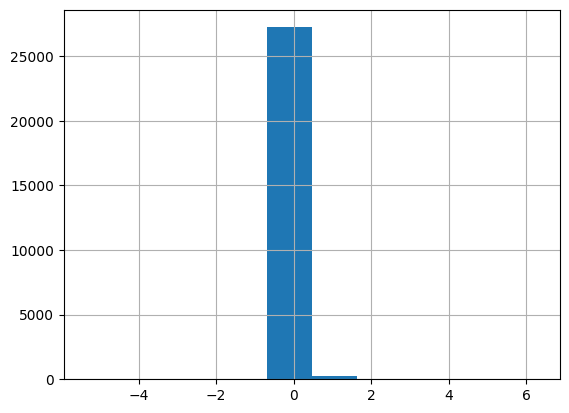

In [30]:
ratio.loc["TP18-M561"].hist(bins=10)


In [6]:
# Step 6 — CNV masking and consensus copy-neutral bin universe (ichorCNA)
import pandas as pd
import numpy as np
import os

RATIO_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"
ICHOR_BASE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/ichorCNA/hg38_1000kb/results/ichorCNA"

SEG_THRESH = 0.10
AUTOSOMES = [f"chr{i}" for i in range(1, 23)]

df = pd.read_csv(RATIO_FILE)

# sample IDs are in the index column written to CSV
df = df.set_index("Unnamed: 0")
df.index.name = "sample"

samples = df.index.tolist()
bin_cols = df.columns.tolist()

print("Samples:", len(samples))
print("Bins:", len(bin_cols))
print("Example sample IDs:", samples[:3])
print("Example bin IDs:", bin_cols[:3])


Samples: 262
Bins: 27520
Example sample IDs: ['TP18-M561', 'TP18-M578', 'TP18-M624']
Example bin IDs: ['chr3_165000000_165100000', 'chr8_112900000_113000000', 'chr13_55700000_55800000']


In [7]:
import pandas as pd
import numpy as np
import os

# -------------------------
# Inputs
# -------------------------
RATIO_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"
ICHOR_BASE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/ichorCNA/hg38_1000kb/results/ichorCNA"

AUTOSOMES = [f"chr{i}" for i in range(1, 23)]
CONS_THRESHOLDS = [0.50, 0.60, 0.70, 0.80, 0.90]

OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/cnv_masking_outputs_event_based"
os.makedirs(OUTDIR, exist_ok=True)

# -------------------------
# Load ratio matrix (samples x bins)
# -------------------------
df = pd.read_csv(RATIO_FILE)
df = df.set_index("Unnamed: 0")
df.index.name = "sample"

samples = df.index.tolist()
bin_cols = df.columns.tolist()

print("Samples:", len(samples))
print("Total bins in ratio file:", len(bin_cols))

# -------------------------
# Parse bin coords from header (chr_start_end)
# -------------------------
def parse_bin(bin_id: str):
    chrom, start, end = bin_id.split("_")
    return chrom, int(start), int(end)

bins_df = pd.DataFrame([parse_bin(b) for b in bin_cols], columns=["chr","start","end"])
bins_df["bin_id"] = bin_cols

# Keep autosomes only for consensus universe
bins_df = bins_df[bins_df["chr"].isin(AUTOSOMES)].reset_index(drop=True)
auto_bin_ids = bins_df["bin_id"].tolist()

print("Autosomal bins:", len(auto_bin_ids))

# -------------------------
# Load ichor segments and return CNV segments (event != NEUT)
# -------------------------
def load_cnv_segments_event(sample: str):
    seg_path = os.path.join(ICHOR_BASE, sample, f"{sample}.seg")
    if not os.path.exists(seg_path):
        return None, seg_path

    seg = pd.read_csv(seg_path, sep="\t")
    seg.columns = [c.lower() for c in seg.columns]

    required = {"chr","start","end","event"}
    if not required.issubset(set(seg.columns)):
        raise ValueError(f"Missing required columns in {seg_path}. Found: {seg.columns.tolist()}")

    seg["chr"] = seg["chr"].astype(str)
    seg.loc[~seg["chr"].str.startswith("chr"), "chr"] = "chr" + seg.loc[~seg["chr"].str.startswith("chr"), "chr"]

    seg = seg[seg["chr"].isin(AUTOSOMES)].copy()

    # CNV segments are those NOT neutral
    cnv = seg[seg["event"].astype(str).str.upper() != "NEUT"][["chr","start","end"]].copy()
    return cnv, seg_path

# -------------------------
# Build mask matrix: True=neutral(keep), False=CNV(mask)
# Rows = bins, Cols = samples
# -------------------------
mask = pd.DataFrame(True, index=auto_bin_ids, columns=samples)

missing_segs = []
for sample in samples:
    cnv_seg, seg_path = load_cnv_segments_event(sample)
    if cnv_seg is None:
        missing_segs.append(sample)
        continue

    if cnv_seg.empty:
        continue

    # per chromosome overlap
    for chrom in cnv_seg["chr"].unique():
        segs = cnv_seg[cnv_seg["chr"] == chrom]
        bchr = bins_df[bins_df["chr"] == chrom]

        seg_starts = segs["start"].to_numpy()
        seg_ends   = segs["end"].to_numpy()

        # loop bins in that chromosome
        for idx, b in bchr.iterrows():
            bs, be = int(b["start"]), int(b["end"])
            overlap = np.any((seg_starts < be) & (seg_ends > bs))
            if overlap:
                mask.loc[b["bin_id"], sample] = False

print("Samples missing .seg files:", len(missing_segs))
if missing_segs:
    pd.Series(missing_segs).to_csv(os.path.join(OUTDIR, "missing_seg_samples.txt"), index=False, header=False)

# Save mask matrix (optional)
mask.astype(int).to_csv(os.path.join(OUTDIR, "cnv_mask_matrix_bins_x_samples.tsv"), sep="\t")

# -------------------------
# Compute neutral_fraction per bin
# -------------------------
neutral_fraction = mask.mean(axis=1)  # fraction of samples where bin is neutral
neutral_fraction_df = neutral_fraction.reset_index()
neutral_fraction_df.columns = ["bin_id", "neutral_fraction"]
neutral_fraction_df.to_csv(os.path.join(OUTDIR, "neutral_fraction_per_bin.tsv"), sep="\t", index=False)

# -------------------------
# Save consensus universes + summary table
# -------------------------
summary_rows = []
for thr in CONS_THRESHOLDS:
    consensus_bins = neutral_fraction[neutral_fraction >= thr].index.tolist()

    out_txt = os.path.join(OUTDIR, f"consensus_neutral_bins_{int(thr*100)}pct.txt")
    with open(out_txt, "w") as f:
        f.write("\n".join(consensus_bins) + "\n")

    summary_rows.append({
        "threshold": thr,
        "n_consensus_bins": len(consensus_bins),
        "pct_of_autosomal_bins": len(consensus_bins) / len(auto_bin_ids) * 100.0
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(os.path.join(OUTDIR, "consensus_bin_counts_summary.tsv"), sep="\t", index=False)

print(summary_df)
print("Wrote outputs to:", OUTDIR)


Samples: 262
Total bins in ratio file: 27520
Autosomal bins: 26175
Samples missing .seg files: 0
   threshold  n_consensus_bins  pct_of_autosomal_bins
0        0.5             22259              85.039160
1        0.6             15841              60.519580
2        0.7              5422              20.714422
3        0.8              1717               6.559694
4        0.9               303               1.157593
Wrote outputs to: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/cnv_masking_outputs_event_based


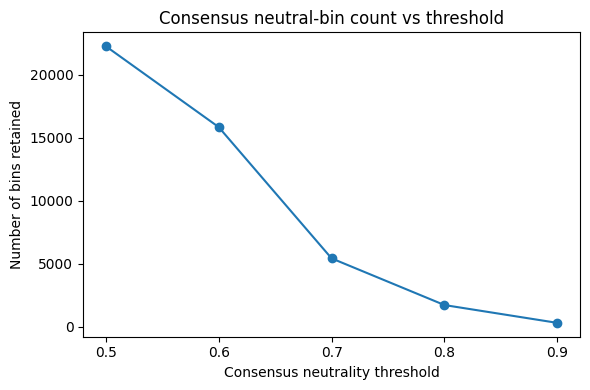

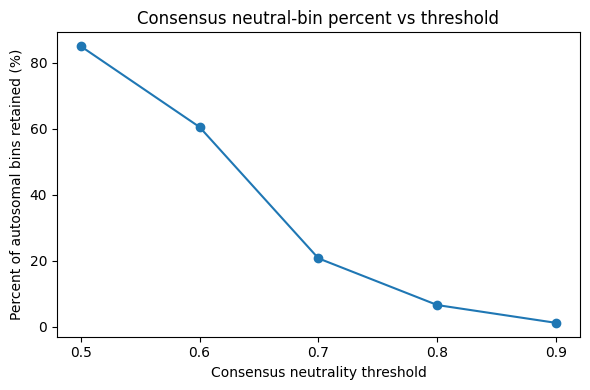

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

summary_path = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/cnv_masking_outputs_event_based/consensus_bin_counts_summary.tsv"

df = pd.read_csv(summary_path, sep="\t").sort_values("threshold")

# Plot 1: number of bins retained
plt.figure(figsize=(6,4))
plt.plot(df["threshold"], df["n_consensus_bins"], marker="o")
plt.xticks(df["threshold"])
plt.xlabel("Consensus neutrality threshold")
plt.ylabel("Number of bins retained")
plt.title("Consensus neutral-bin count vs threshold")
plt.tight_layout()
plt.savefig(summary_path.replace("consensus_bin_counts_summary.tsv","consensus_bins_vs_threshold.count.png"), dpi=200)
plt.show()

# Plot 2: percent retained
plt.figure(figsize=(6,4))
plt.plot(df["threshold"], df["pct_of_autosomal_bins"], marker="o")
plt.xticks(df["threshold"])
plt.xlabel("Consensus neutrality threshold")
plt.ylabel("Percent of autosomal bins retained (%)")
plt.title("Consensus neutral-bin percent vs threshold")
plt.tight_layout()
plt.savefig(summary_path.replace("consensus_bin_counts_summary.tsv","consensus_bins_vs_threshold.percent.png"), dpi=200)
plt.show()


Loaded ratio matrix: (262, 27520)
Universe bins (70%) present in ratio matrix: 5422
Metadata samples present in ratio: 80

Top 3 metastatic sites (single-site samples):
liver    24
bone     14
brain    12
Name: metastatic_sites, dtype: int64

Analysis set:
  Samples: 50
  Bins: 5422
  Sites: {'liver': 24, 'bone': 14, 'brain': 12}

Saved analysis matrix: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/site_comparison_universe70/ratio_log2_universe70_top3sites.tsv
Saved site fingerprints: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/site_comparison_universe70/site_fingerprints_median_log2.tsv


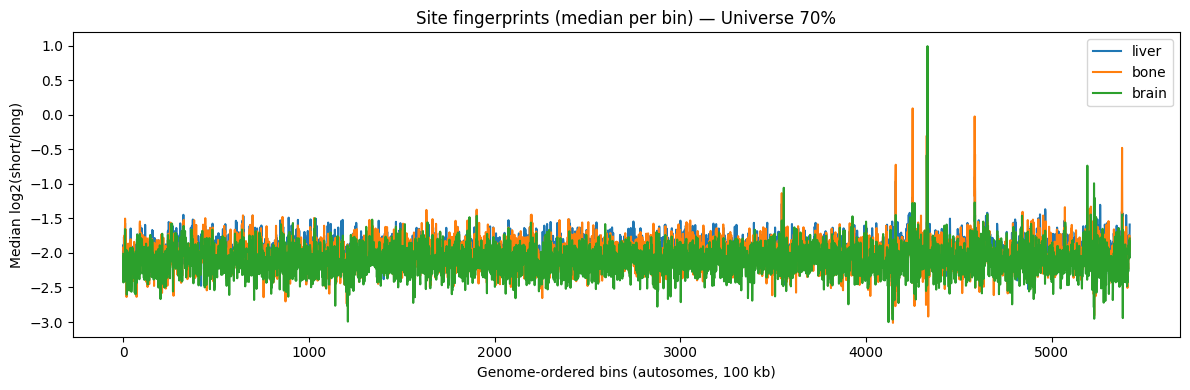

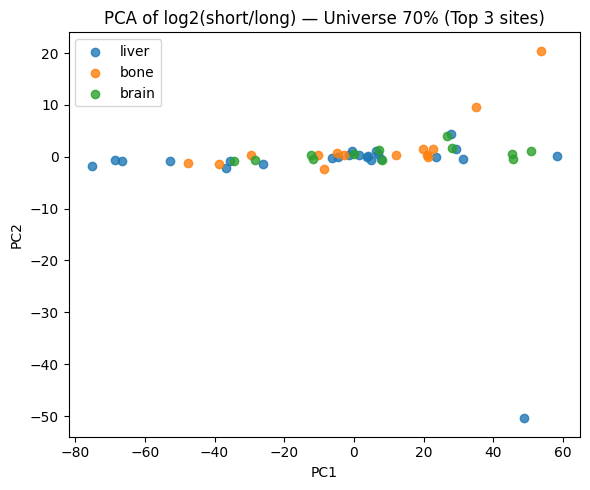

Saved per-bin KW results: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/site_comparison_universe70/per_bin_KW_top3sites_universe70.tsv


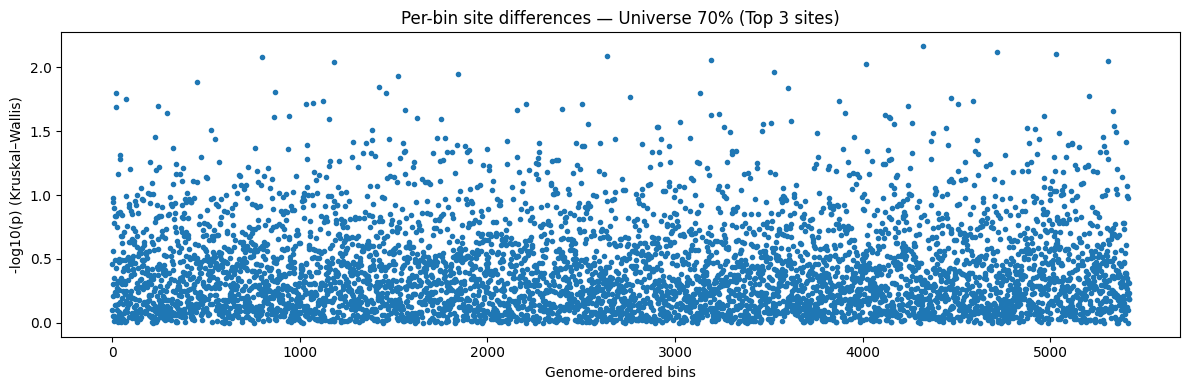


DONE. Outputs in: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/site_comparison_universe70


In [1]:
# First perform at 0.5 threshold followed by 0.6 and 0.7
import os
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt

# ----------------------------
# Paths
# ----------------------------
RATIO_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"

CNV_OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/cnv_masking_outputs_event_based"
UNIVERSE_70 = os.path.join(CNV_OUTDIR, "consensus_neutral_bins_70pct.txt")

META_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_one_per_bios_site.csv"

OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/site_comparison_universe70"
os.makedirs(OUTDIR, exist_ok=True)

TOPK = 3

# ----------------------------
# Parse bin coordinates from header chr_start_end
# ----------------------------
def parse_bin(bin_id: str):
    chrom, start, end = bin_id.split("_")
    return chrom, int(start), int(end)

# ----------------------------
# Load ratio matrix (samples x bins)
# ----------------------------
ratio = pd.read_csv(RATIO_FILE)
ratio = ratio.set_index("Unnamed: 0")
ratio.index.name = "sample"

print("Loaded ratio matrix:", ratio.shape)  # (samples, bins)

# ----------------------------
# Load 0.5 consensus universe bins and subset
# ----------------------------
with open(UNIVERSE_70, "r") as f:
    universe_bins = [line.strip() for line in f if line.strip()]

universe_bins = [b for b in universe_bins if b in ratio.columns]
print("Universe bins (70%) present in ratio matrix:", len(universe_bins))

ratio_u = ratio[universe_bins].copy()

# Optional: log2 transform of ratio
# (many people analyze log2(short/long); avoids skew)
ratio_u_log2 = np.log2(ratio_u.replace(0, np.nan))

# ----------------------------
# Load metastatic site metadata and print top 3 sites
# ----------------------------
meta = pd.read_csv(META_FILE)
# expected columns: id, metastatic_sites
meta.columns = [c.strip() for c in meta.columns]

if "id" not in meta.columns or "metastatic_sites" not in meta.columns:
    raise ValueError(f"Metadata must contain columns 'id' and 'metastatic_sites'. Found: {meta.columns.tolist()}")

# align naming
meta["id"] = meta["id"].astype(str).str.strip()
meta["metastatic_sites"] = meta["metastatic_sites"].astype(str).str.strip().str.lower()

# keep only samples that exist in ratio matrix
meta = meta[meta["id"].isin(ratio_u_log2.index)].copy()
print("Metadata samples present in ratio:", meta.shape[0])

# top 3 metastatic sites
site_counts = meta["metastatic_sites"].value_counts()
top_sites = site_counts.head(TOPK)

print("\nTop 3 metastatic sites (single-site samples):")
print(top_sites)

top_site_list = top_sites.index.tolist()

# subset meta + ratio to only those sites
meta_top = meta[meta["metastatic_sites"].isin(top_site_list)].copy()
keep_samples = meta_top["id"].tolist()

X = ratio_u_log2.loc[keep_samples].copy()
y = meta_top.set_index("id").loc[keep_samples, "metastatic_sites"]

print("\nAnalysis set:")
print("  Samples:", X.shape[0])
print("  Bins:", X.shape[1])
print("  Sites:", y.value_counts().to_dict())

# ----------------------------
# Save the filtered matrix used for analysis
# ----------------------------
X_out = os.path.join(OUTDIR, "ratio_log2_universe70_top3sites.tsv")
X.join(y.rename("site")).to_csv(X_out, sep="\t", index=True)
print("\nSaved analysis matrix:", X_out)

# ----------------------------
# Site fingerprints (median per bin) and plots
# ----------------------------
# Build bin coordinate table for sorting/plotting
bins_df = pd.DataFrame([parse_bin(b) for b in X.columns], columns=["chr", "start", "end"])
bins_df["bin_id"] = X.columns
bins_df["chr_num"] = bins_df["chr"].str.replace("chr", "", regex=False).astype(int)
bins_df = bins_df.sort_values(["chr_num", "start"]).reset_index(drop=True)

# compute per-site median profile (bins)
fingerprints = {}
for site in top_site_list:
    sids = y.index[y == site].tolist()
    fingerprints[site] = X.loc[sids].median(axis=0, skipna=True)

fp = pd.DataFrame(fingerprints)  # index=bins, columns=sites
fp = fp.loc[bins_df["bin_id"]]   # reorder bins

fp_out = os.path.join(OUTDIR, "site_fingerprints_median_log2.tsv")
fp.to_csv(fp_out, sep="\t", index=True)
print("Saved site fingerprints:", fp_out)

# plot: genome-wide line plot for each site (log2 ratio)
plt.figure(figsize=(12, 4))
xpos = np.arange(fp.shape[0])
for site in top_site_list:
    plt.plot(xpos, fp[site].values, label=site)
plt.xlabel("Genome-ordered bins (autosomes, 100 kb)")
plt.ylabel("Median log2(short/long)")
plt.title("Site fingerprints (median per bin) — Universe 70%")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "site_fingerprints_universe70.png"), dpi=200)
plt.show()

# ----------------------------
# PCA on samples (simple SVD; no sklearn needed)
# ----------------------------
# center features by bin median
X_centered = X - X.median(axis=0, skipna=True)

# fill NaNs with 0 after centering (reasonable for PCA)
X_centered = X_centered.fillna(0.0)

U, S, VT = np.linalg.svd(X_centered.values, full_matrices=False)
PC = U[:, :2] * S[:2]  # scores for PC1/PC2

pca_df = pd.DataFrame(PC, columns=["PC1", "PC2"], index=X_centered.index)
pca_df["site"] = y.values
pca_df.to_csv(os.path.join(OUTDIR, "PCA_scores_universe70.tsv"), sep="\t", index=True)

plt.figure(figsize=(6, 5))
for site in top_site_list:
    idx = (pca_df["site"] == site)
    plt.scatter(pca_df.loc[idx, "PC1"], pca_df.loc[idx, "PC2"], label=site, alpha=0.8)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of log2(short/long) — Universe 70% (Top 3 sites)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "PCA_universe70_top3sites.png"), dpi=200)
plt.show()

# ----------------------------
# Per-bin stats: Kruskal–Wallis across 3 sites + BH-FDR
# ----------------------------
# For each bin: KW test across the 3 groups
pvals = []
stat = []
for b in X.columns:
    groups = [X.loc[y.index[y == site], b].dropna().values for site in top_site_list]
    # require some minimal data in each group
    if any(len(g) < 5 for g in groups):
        pvals.append(np.nan)
        stat.append(np.nan)
        continue
    H, p = stats.kruskal(*groups)
    pvals.append(p)
    stat.append(H)

res = pd.DataFrame({
    "bin_id": X.columns,
    "H_stat": stat,
    "pval": pvals
})

# add coords
coord_map = bins_df.set_index("bin_id")[["chr", "start", "end"]]
res = res.join(coord_map, on="bin_id")

# BH-FDR (ignore NaNs)
mask_valid = res["pval"].notna()
fdr = np.full(res.shape[0], np.nan)
fdr[mask_valid.values] = multipletests(res.loc[mask_valid, "pval"].values, method="fdr_bh")[1]
res["fdr_bh"] = fdr

res = res.sort_values(["fdr_bh", "pval"], na_position="last")
res_out = os.path.join(OUTDIR, "per_bin_KW_top3sites_universe70.tsv")
res.to_csv(res_out, sep="\t", index=False)
print("Saved per-bin KW results:", res_out)

# quick volcano-like: -log10(p) vs position index (not true Manhattan but useful)
plt.figure(figsize=(12, 4))
p = res.set_index("bin_id").loc[bins_df["bin_id"], "pval"].values
plt.plot(-np.log10(p), marker=".", linestyle="None")
plt.xlabel("Genome-ordered bins")
plt.ylabel("-log10(p) (Kruskal–Wallis)")
plt.title("Per-bin site differences — Universe 70% (Top 3 sites)")
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "per_bin_KW_universe70_top3sites.png"), dpi=200)
plt.show()

print("\nDONE. Outputs in:", OUTDIR)


Top 3 metastatic sites: ['liver', 'bone', 'brain']

Universe 0.5: 22259 bins


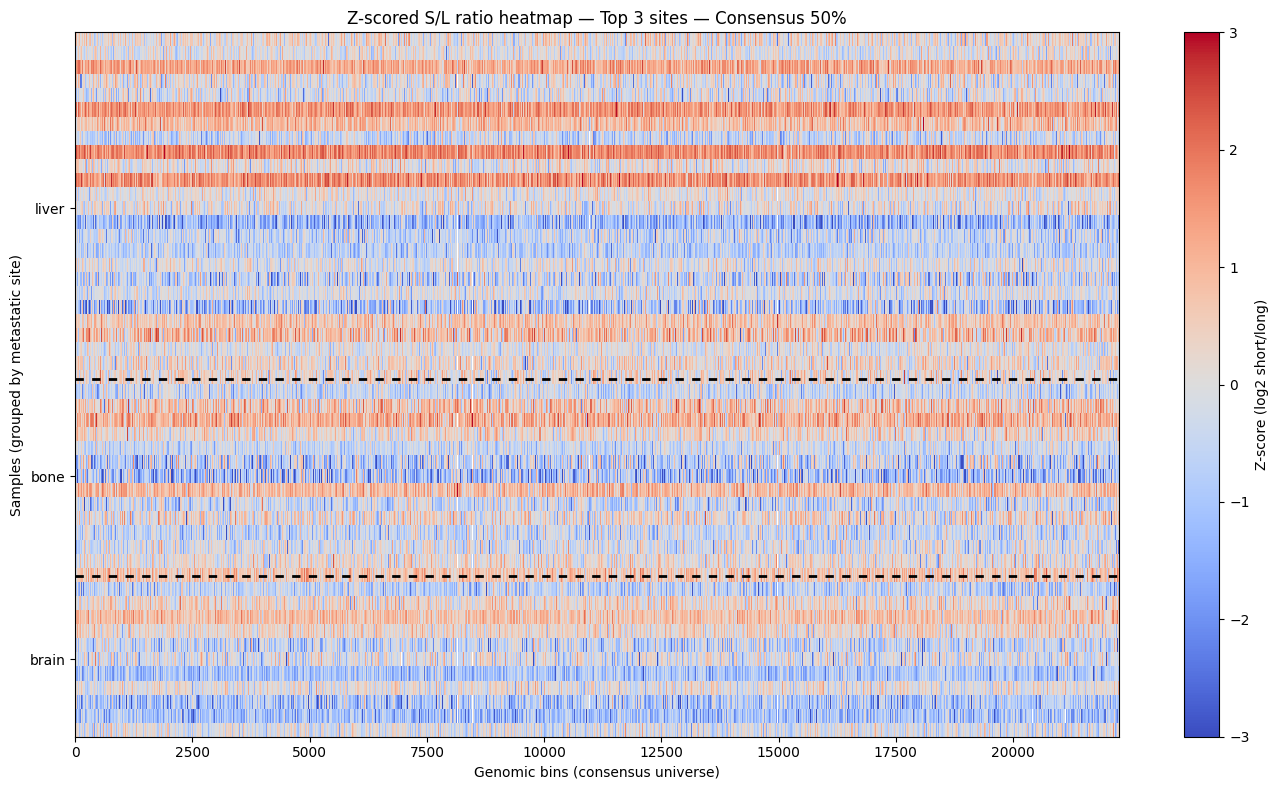

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/zscore_heatmaps/zscore_heatmap_top3sites_universe_50pct.png

Universe 0.6: 15841 bins


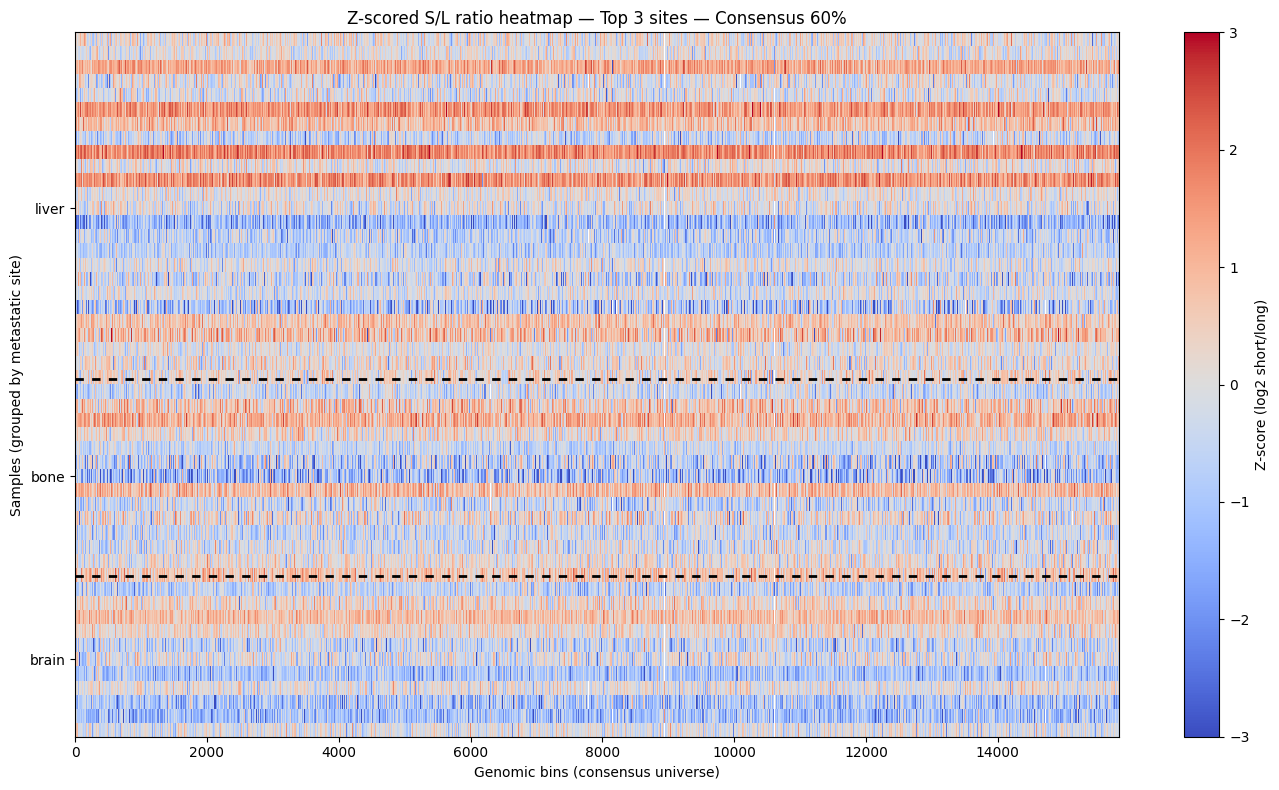

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/zscore_heatmaps/zscore_heatmap_top3sites_universe_60pct.png

Universe 0.7: 5422 bins


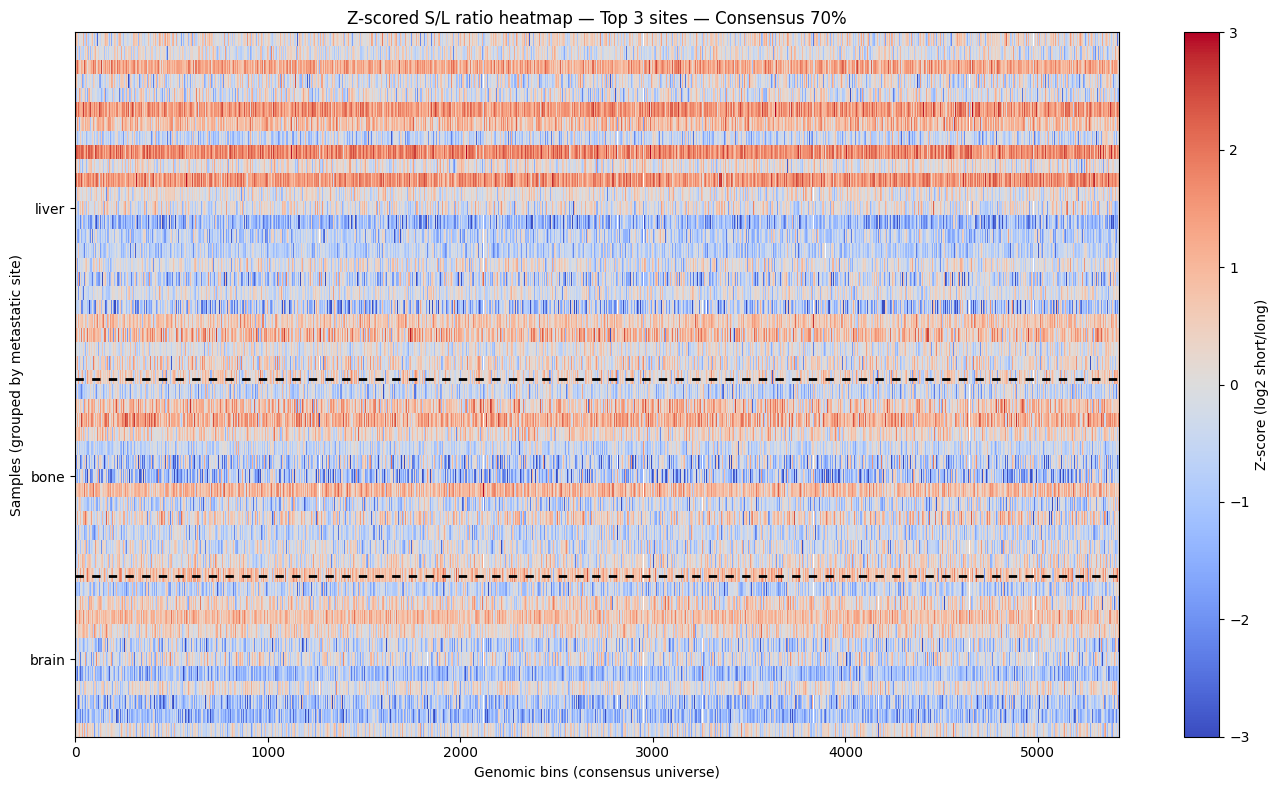

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/zscore_heatmaps/zscore_heatmap_top3sites_universe_70pct.png


In [2]:
# Z-scored S/L heatmaps for 0.5, 0.6, 0.7
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Paths
# -----------------------------
RATIO_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"

CNV_OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/cnv_masking_outputs_event_based"

META_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_one_per_bios_site.csv"

OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/zscore_heatmaps"
os.makedirs(OUTDIR, exist_ok=True)

THRESHOLDS = [0.5, 0.6, 0.7]

# -----------------------------
# Load S/L ratio matrix
# -----------------------------
ratio = pd.read_csv(RATIO_FILE)
ratio = ratio.set_index("Unnamed: 0")
ratio.index.name = "sample"

# log2 transform
ratio = np.log2(ratio.replace(0, np.nan))

# -----------------------------
# Load metastatic site metadata
# -----------------------------
meta = pd.read_csv(META_FILE)
meta["id"] = meta["id"].astype(str)
meta["metastatic_sites"] = meta["metastatic_sites"].astype(str).str.lower()

# Keep only samples present in ratio matrix
meta = meta[meta["id"].isin(ratio.index)].copy()
meta = meta.set_index("id")

site_order = meta["metastatic_sites"].value_counts().index.tolist()

# -----------------------------
# z-score per bin
# -----------------------------
def zscore_by_bin(df):
    mu = df.mean(axis=0, skipna=True)
    sd = df.std(axis=0, skipna=True)
    return (df - mu) / sd

# -----------------------------
# Determine TOP 3 sites once (based on available samples)
# -----------------------------
site_counts = meta["metastatic_sites"].value_counts()
top3_sites = site_counts.head(3).index.tolist()
print("Top 3 metastatic sites:", top3_sites)

# Keep only metadata for those top3 sites
meta_top = meta[meta["metastatic_sites"].isin(top3_sites)].copy()

# Fix site order to be the top3 list (largest -> smaller)
site_order = top3_sites

# -----------------------------
# Loop over universes
# -----------------------------
for thr in THRESHOLDS:

    universe_file = os.path.join(
        CNV_OUTDIR, f"consensus_neutral_bins_{int(thr*100)}pct.txt"
    )

    with open(universe_file) as f:
        bins = [x.strip() for x in f if x.strip()]

    bins = [b for b in bins if b in ratio.columns]
    print(f"\nUniverse {thr}: {len(bins)} bins")

    # Subset matrix to universe bins and TOP 3 site samples only
    X = ratio[bins].copy()
    X = X.loc[meta_top.index]

    # Z-score across samples (per bin) -- recompute AFTER top3 subsetting
    Z = zscore_by_bin(X)

    # Order samples by your top3 frequency order
    meta_ord = meta_top.copy()
    meta_ord["metastatic_sites"] = pd.Categorical(
        meta_ord["metastatic_sites"], categories=site_order, ordered=True
    )
    meta_ord = meta_ord.sort_values("metastatic_sites")
    Z = Z.loc[meta_ord.index]

    # Compute boundaries between site blocks
    site_sizes = (
        meta_ord["metastatic_sites"]
        .value_counts()
        .reindex(site_order)
        .fillna(0)
        .astype(int)
    )
    boundaries = np.cumsum(site_sizes.values)[:-1]  # exclude last block end

    # -----------------------------
    # Plot heatmap (TOP 3 sites only)
    # -----------------------------
    plt.figure(figsize=(14, 8))
    plt.imshow(
        Z.values,
        aspect="auto",
        interpolation="nearest",
        cmap="coolwarm",
        vmin=-3,
        vmax=3
    )
    plt.colorbar(label="Z-score (log2 short/long)")

    # Add separator lines between metastatic site blocks
    for b in boundaries:
        plt.axhline(b + 0.1, color="black", linewidth=2.0, linestyle=(0, (3, 3)))

    # Y-axis labels at block midpoints
    yticks, ylabels = [], []
    start = 0
    for site in site_order:
        n = (meta_ord["metastatic_sites"] == site).sum()
        if n > 0:
            yticks.append(start + n / 2)
            ylabels.append(site)
            start += n

    plt.yticks(yticks, ylabels)
    plt.xlabel("Genomic bins (consensus universe)")
    plt.ylabel("Samples (grouped by metastatic site)")
    plt.title(f"Z-scored S/L ratio heatmap — Top 3 sites — Consensus {int(thr*100)}%")

    outpng = os.path.join(
        OUTDIR, f"zscore_heatmap_top3sites_universe_{int(thr*100)}pct.png"
    )

    plt.tight_layout()
    plt.savefig(outpng, dpi=200)
    plt.show()
    plt.close()
    print(f"Saved: {outpng}")



Top 3 metastatic sites: ['liver', 'bone', 'brain']

Universe 0.5: 22259 bins


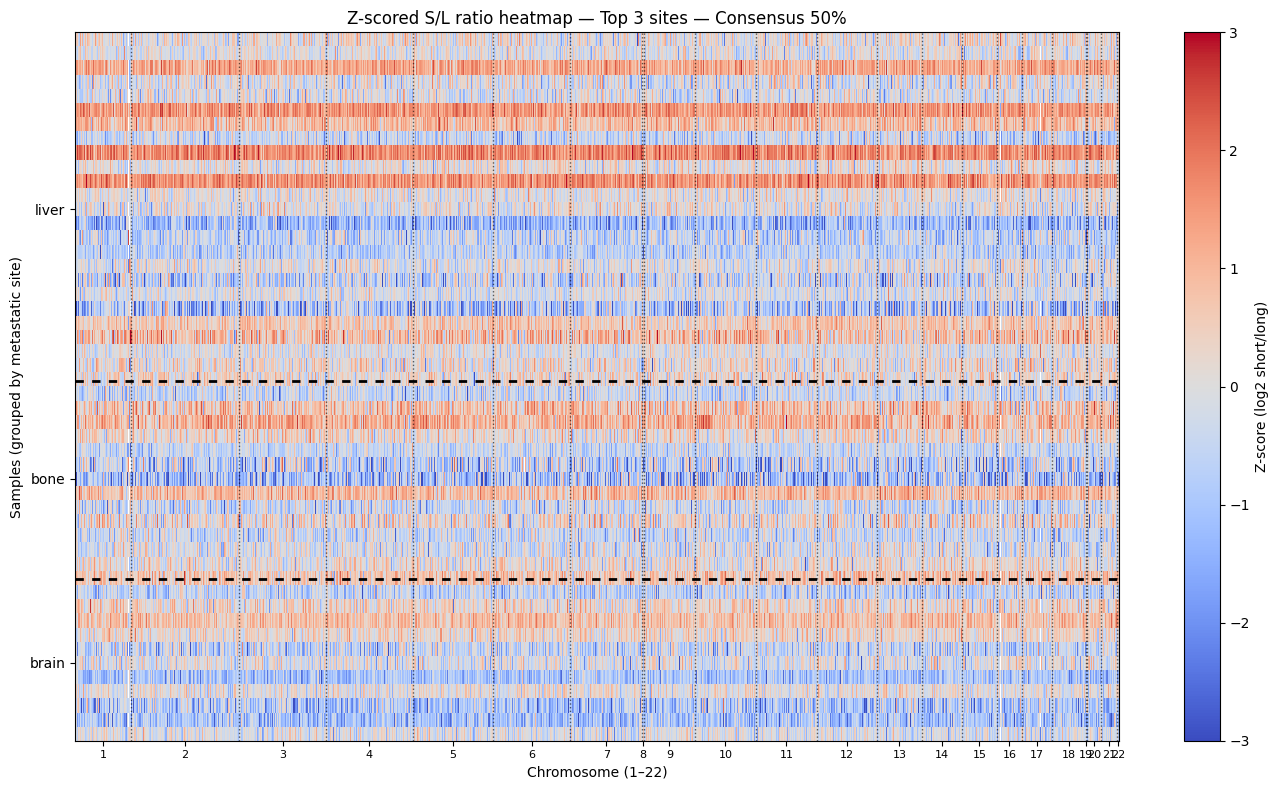

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/zscore_heatmaps/zscore_heatmap_top3sites_universe_50pct_chr.png

Universe 0.6: 15841 bins


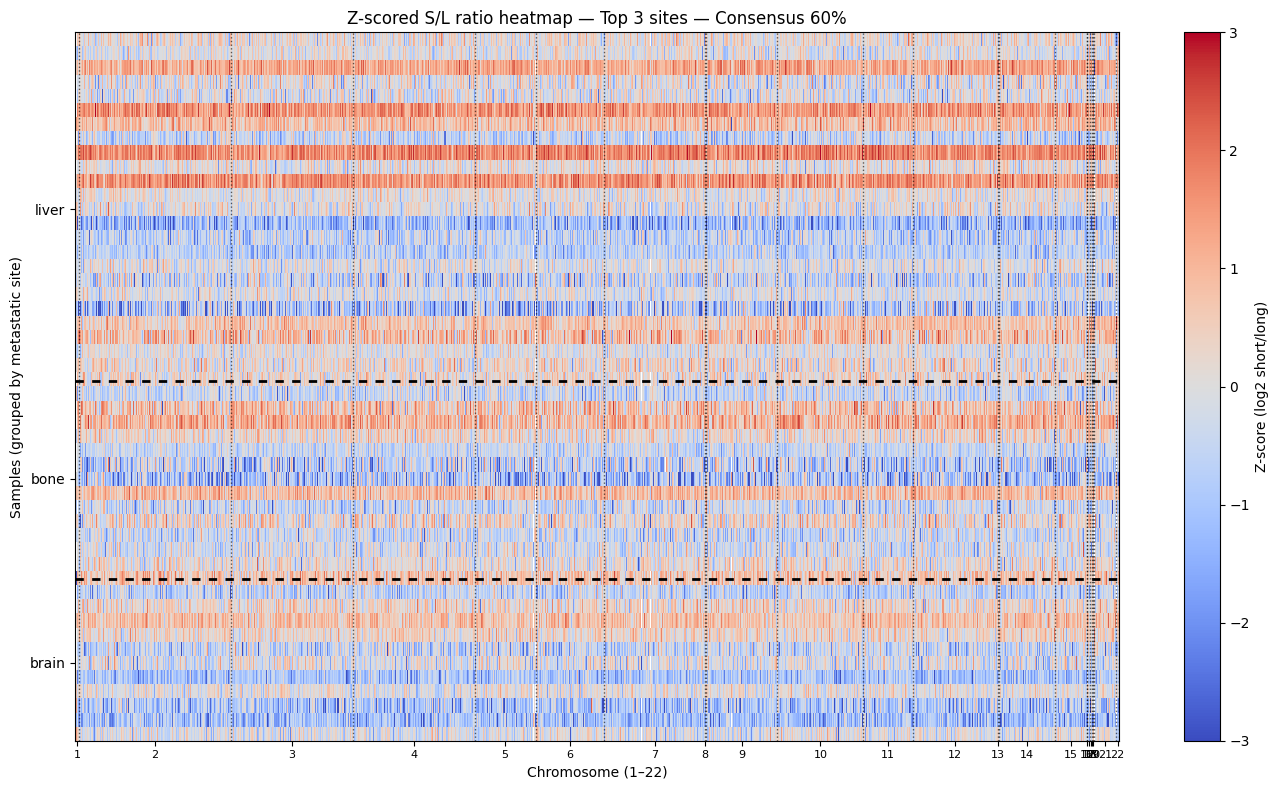

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/zscore_heatmaps/zscore_heatmap_top3sites_universe_60pct_chr.png

Universe 0.7: 5422 bins


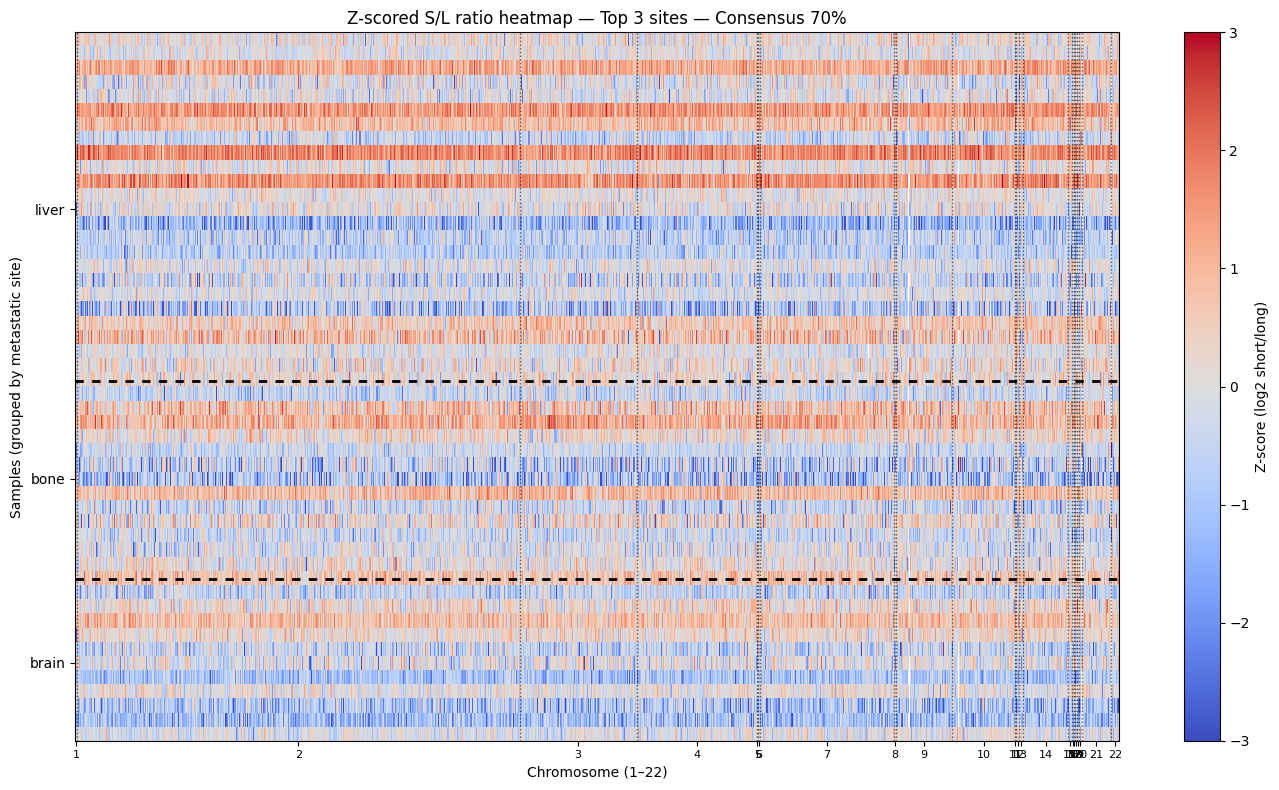

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/zscore_heatmaps/zscore_heatmap_top3sites_universe_70pct_chr.png


In [4]:
# Z-scored S/L heatmaps for 0.5, 0.6, 0.7 (TOP 3 sites) + chr1–chr22 x-axis
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Paths
# -----------------------------
RATIO_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"
CNV_OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/cnv_masking_outputs_event_based"
META_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_one_per_bios_site.csv"

OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/zscore_heatmaps"
os.makedirs(OUTDIR, exist_ok=True)

THRESHOLDS = [0.5, 0.6, 0.7]
CHR_ORDER = [f"chr{i}" for i in range(1, 23)]

# -----------------------------
# Load S/L ratio matrix
# -----------------------------
ratio = pd.read_csv(RATIO_FILE)
ratio = ratio.set_index("Unnamed: 0")
ratio.index.name = "sample"

# log2 transform
ratio = np.log2(ratio.replace(0, np.nan))

# -----------------------------
# Load metastatic site metadata
# -----------------------------
meta = pd.read_csv(META_FILE)
meta["id"] = meta["id"].astype(str)
meta["metastatic_sites"] = meta["metastatic_sites"].astype(str).str.lower()

meta = meta[meta["id"].isin(ratio.index)].copy()
meta = meta.set_index("id")

# -----------------------------
# z-score per bin
# -----------------------------
def zscore_by_bin(df):
    mu = df.mean(axis=0, skipna=True)
    sd = df.std(axis=0, skipna=True)
    return (df - mu) / sd

# -----------------------------
# Bin parsing + genome ordering
# -----------------------------
def parse_bin(bin_id: str):
    # expects chrN_start_end
    chrom, start, end = bin_id.split("_")
    return chrom, int(start), int(end)

def genome_sort_bins(bin_list):
    rows = []
    for b in bin_list:
        chrom, start, end = parse_bin(b)
        if chrom in CHR_ORDER:
            chrom_num = int(chrom.replace("chr", ""))
            rows.append((chrom_num, start, b))
    rows.sort()
    return [b for _, _, b in rows]

def chr_ticks_and_boundaries(ordered_bins):
    # ordered_bins must be genome-ordered
    chroms = [b.split("_")[0] for b in ordered_bins]
    chroms = np.array(chroms)

    chr_mid = {}
    boundaries = []
    for chrom in CHR_ORDER:
        idx = np.where(chroms == chrom)[0]
        if len(idx) == 0:
            continue
        s = idx.min()
        e = idx.max()
        chr_mid[chrom] = (s + e) / 2
        boundaries.append(e + 0.5)
    return chr_mid, boundaries

# -----------------------------
# Determine TOP 3 sites once
# -----------------------------
site_counts = meta["metastatic_sites"].value_counts()
top3_sites = site_counts.head(3).index.tolist()
print("Top 3 metastatic sites:", top3_sites)

meta_top = meta[meta["metastatic_sites"].isin(top3_sites)].copy()
site_order = top3_sites  # keep frequency order

# -----------------------------
# Loop over universes
# -----------------------------
for thr in THRESHOLDS:

    universe_file = os.path.join(CNV_OUTDIR, f"consensus_neutral_bins_{int(thr*100)}pct.txt")
    with open(universe_file) as f:
        bins = [x.strip() for x in f if x.strip()]

    # keep only bins present + autosomes
    bins = [b for b in bins if b in ratio.columns and b.split("_")[0] in CHR_ORDER]
    print(f"\nUniverse {thr}: {len(bins)} bins")

    # genome-order the bins (critical for chr x-axis)
    bins_sorted = genome_sort_bins(bins)

    # Subset matrix to universe bins and TOP 3 site samples only
    X = ratio[bins_sorted].copy()
    X = X.loc[meta_top.index]

    # Z-score AFTER top3 subsetting
    Z = zscore_by_bin(X)

    # Order samples by site order
    meta_ord = meta_top.copy()
    meta_ord["metastatic_sites"] = pd.Categorical(
        meta_ord["metastatic_sites"], categories=site_order, ordered=True
    )
    meta_ord = meta_ord.sort_values("metastatic_sites")
    Z = Z.loc[meta_ord.index]

    # Compute boundaries between site blocks (y separators)
    site_sizes = (
        meta_ord["metastatic_sites"]
        .value_counts()
        .reindex(site_order)
        .fillna(0)
        .astype(int)
    )
    y_boundaries = np.cumsum(site_sizes.values)[:-1]

    # Compute chromosome ticks and x boundaries
    chr_mid, x_boundaries = chr_ticks_and_boundaries(bins_sorted)

    # -----------------------------
    # Plot heatmap
    # -----------------------------
    plt.figure(figsize=(14, 8))
    plt.imshow(
        Z.values,
        aspect="auto",
        interpolation="nearest",
        cmap="coolwarm",
        vmin=-3,
        vmax=3
    )
    plt.colorbar(label="Z-score (log2 short/long)")

    # Horizontal dotted separators between metastatic site blocks
    for b in y_boundaries:
        plt.axhline(b + 0.1, color="black", linewidth=2.0, linestyle=(0, (3, 3)))

    # Vertical dotted separators between chromosomes
    for xb in x_boundaries:
        plt.axvline(xb, color="black", linewidth=1.0, linestyle=":", alpha=0.6)

    # Y-axis labels at block midpoints
    yticks, ylabels = [], []
    start = 0
    for site in site_order:
        n = (meta_ord["metastatic_sites"] == site).sum()
        if n > 0:
            yticks.append(start + n / 2)
            ylabels.append(site)
            start += n
    plt.yticks(yticks, ylabels)

    # X-axis chromosome labels at midpoints
    xticks = list(chr_mid.values())
    xlabels = [c.replace("chr", "") for c in chr_mid.keys()]
    plt.xticks(xticks, xlabels, fontsize=8)
    plt.xlabel("Chromosome (1–22)")

    plt.ylabel("Samples (grouped by metastatic site)")
    plt.title(f"Z-scored S/L ratio heatmap — Top 3 sites — Consensus {int(thr*100)}%")

    outpng = os.path.join(OUTDIR, f"zscore_heatmap_top3sites_universe_{int(thr*100)}pct_chr.png")
    plt.tight_layout()
    plt.savefig(outpng, dpi=200)
    plt.show()
    plt.close()
    print(f"Saved: {outpng}")


In [5]:
# Make LOLA BEDs for top3 sites (0.5/0.6/0.7)
# This uses Mann–Whitney (Wilcoxon rank-sum) for site vs all other samples (within top3) per bin, then BH-FDR.
import os
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

# -----------------------------
# Paths
# -----------------------------
RATIO_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"

CNV_OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/cnv_masking_outputs_event_based"
MASK_FILE  = os.path.join(CNV_OUTDIR, "cnv_mask_matrix_bins_x_samples.tsv")

META_FILE  = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_one_per_bios_site.csv"

OUTDIR_BASE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites"
os.makedirs(OUTDIR_BASE, exist_ok=True)

THRESHOLDS = [0.5, 0.6, 0.7]
FDR_CUTOFF = 0.1
MIN_PER_GROUP = 8   # skip bins with <8 samples in either group after CNV masking
AUTOSOMES = [f"chr{i}" for i in range(1, 23)]

# -----------------------------
# Helpers
# -----------------------------
def parse_bin(bin_id: str):
    chrom, start, end = bin_id.split("_")
    return chrom, int(start), int(end)

def genome_sort_bins(bin_list):
    rows = []
    for b in bin_list:
        chrom, start, _ = parse_bin(b)
        if chrom in AUTOSOMES:
            rows.append((int(chrom.replace("chr","")), start, b))
    rows.sort()
    return [b for _, _, b in rows]

# -----------------------------
# Load ratio (samples x bins)
# -----------------------------
ratio = pd.read_csv(RATIO_FILE).set_index("Unnamed: 0")
ratio.index.name = "sample"
ratio = np.log2(ratio.replace(0, np.nan))  # log2(S/L)

# -----------------------------
# Load metastatic site metadata (single-site)
# -----------------------------
meta = pd.read_csv(META_FILE)
meta["id"] = meta["id"].astype(str).str.strip()
meta["metastatic_sites"] = meta["metastatic_sites"].astype(str).str.lower().str.strip()

meta = meta[meta["id"].isin(ratio.index)].copy()
meta = meta.set_index("id")

# Top 3 sites by count
top3_sites = meta["metastatic_sites"].value_counts().head(3).index.tolist()
print("Top 3 sites:", top3_sites)

meta_top = meta[meta["metastatic_sites"].isin(top3_sites)].copy()
samples_top = meta_top.index.tolist()

# -----------------------------
# Load CNV mask (bins x samples), 1=keep(neutral), 0=mask(CNV)
# -----------------------------
mask = pd.read_csv(MASK_FILE, sep="\t", index_col=0)
# Make sure mask is bins x samples
# (your file name implies bins_x_samples)
# Align to ratio bins/samples later

# -----------------------------
# Main loop over universes
# -----------------------------
for thr in THRESHOLDS:
    outdir = os.path.join(OUTDIR_BASE, f"universe_{int(thr*100)}pct")
    os.makedirs(outdir, exist_ok=True)

    universe_file = os.path.join(CNV_OUTDIR, f"consensus_neutral_bins_{int(thr*100)}pct.txt")
    with open(universe_file) as f:
        bins = [x.strip() for x in f if x.strip()]

    # Keep autosomes + bins present
    bins = [b for b in bins if (b in ratio.columns and b.split("_")[0] in AUTOSOMES)]
    bins = genome_sort_bins(bins)
    print(f"\nUniverse {thr}: {len(bins)} bins")

    # Universe BED for LOLA (hg38)
    universe_bed = os.path.join(outdir, f"universe_{int(thr*100)}pct.hg38.bed")
    ub = pd.DataFrame([parse_bin(b) for b in bins], columns=["chr","start","end"])
    ub.to_csv(universe_bed, sep="\t", header=False, index=False)

    # Subset ratio to top3 samples + universe bins
    X = ratio.loc[samples_top, bins].copy()

    # Align CNV mask to same bins/samples and apply it (mask out CNV bins per sample)
    # mask is bins x samples with 1 keep, 0 mask
    mask_sub = mask.loc[mask.index.intersection(bins), mask.columns.intersection(samples_top)].copy()

    # Ensure same ordering
    mask_sub = mask_sub.loc[bins, samples_top]
    # apply: set X[sample, bin]=NaN where mask==0
    X_masked = X.copy()
    X_masked.loc[:, :] = np.where(mask_sub.T.values == 1, X.values, np.nan)

    # For each site, test site vs others (within top3) per bin
    for site in top3_sites:
        idx_site = meta_top.index[meta_top["metastatic_sites"] == site].tolist()
        idx_other = meta_top.index[meta_top["metastatic_sites"] != site].tolist()

        pvals = []
        effects = []
        n_site_list = []
        n_other_list = []

        for b in bins:
            a = X_masked.loc[idx_site, b].dropna().values
            c = X_masked.loc[idx_other, b].dropna().values

            n_site_list.append(len(a))
            n_other_list.append(len(c))

            if len(a) < MIN_PER_GROUP or len(c) < MIN_PER_GROUP:
                pvals.append(np.nan)
                effects.append(np.nan)
                continue

            # effect = median(site) - median(others)
            eff = np.nanmedian(a) - np.nanmedian(c)
            effects.append(eff)

            # Mann-Whitney U (two-sided)
            p = stats.mannwhitneyu(a, c, alternative="two-sided").pvalue
            pvals.append(p)

        res = pd.DataFrame({
            "bin": bins,
            "chr": [parse_bin(b)[0] for b in bins],
            "start": [parse_bin(b)[1] for b in bins],
            "end": [parse_bin(b)[2] for b in bins],
            "site": site,
            "n_site": n_site_list,
            "n_other": n_other_list,
            "effect_median_log2SL": effects,
            "pval": pvals
        })

        # BH-FDR
        valid = res["pval"].notna()
        q = np.full(len(res), np.nan)
        if valid.sum() > 0:
            q[valid.values] = multipletests(res.loc[valid, "pval"].values, method="fdr_bh")[1]
        res["fdr_bh"] = q

        # Save stats table
        out_stats = os.path.join(outdir, f"{site}_vs_other_stats_universe_{int(thr*100)}pct.tsv")
        res.to_csv(out_stats, sep="\t", index=False)

        # Define shorter/longer bins for LOLA
        # Higher log2(S/L) => more short fragments => "shorter"
        sig = res[(res["fdr_bh"] < FDR_CUTOFF) & res["effect_median_log2SL"].notna()].copy()

        shorter = sig[sig["effect_median_log2SL"] > 0]
        longer  = sig[sig["effect_median_log2SL"] < 0]

        out_short = os.path.join(outdir, f"{site}_shorter_bins_FDR{FDR_CUTOFF}_universe_{int(thr*100)}pct.hg38.bed")
        out_long  = os.path.join(outdir, f"{site}_longer_bins_FDR{FDR_CUTOFF}_universe_{int(thr*100)}pct.hg38.bed")

        shorter[["chr","start","end"]].to_csv(out_short, sep="\t", header=False, index=False)
        longer[["chr","start","end"]].to_csv(out_long,  sep="\t", header=False, index=False)

        print(f"  {site}: sig={sig.shape[0]} shorter={shorter.shape[0]} longer={longer.shape[0]}")
        print(f"    wrote: {os.path.basename(out_short)}")
        print(f"    wrote: {os.path.basename(out_long)}")

print("\nDONE — LOLA input BEDs created under:", OUTDIR_BASE)


Top 3 sites: ['liver', 'bone', 'brain']

Universe 0.5: 22259 bins
  liver: sig=0 shorter=0 longer=0
    wrote: liver_shorter_bins_FDR0.1_universe_50pct.hg38.bed
    wrote: liver_longer_bins_FDR0.1_universe_50pct.hg38.bed
  bone: sig=0 shorter=0 longer=0
    wrote: bone_shorter_bins_FDR0.1_universe_50pct.hg38.bed
    wrote: bone_longer_bins_FDR0.1_universe_50pct.hg38.bed
  brain: sig=0 shorter=0 longer=0
    wrote: brain_shorter_bins_FDR0.1_universe_50pct.hg38.bed
    wrote: brain_longer_bins_FDR0.1_universe_50pct.hg38.bed

Universe 0.6: 15841 bins
  liver: sig=0 shorter=0 longer=0
    wrote: liver_shorter_bins_FDR0.1_universe_60pct.hg38.bed
    wrote: liver_longer_bins_FDR0.1_universe_60pct.hg38.bed
  bone: sig=0 shorter=0 longer=0
    wrote: bone_shorter_bins_FDR0.1_universe_60pct.hg38.bed
    wrote: bone_longer_bins_FDR0.1_universe_60pct.hg38.bed
  brain: sig=0 shorter=0 longer=0
    wrote: brain_shorter_bins_FDR0.1_universe_60pct.hg38.bed
    wrote: brain_longer_bins_FDR0.1_universe

In [7]:
# Computes η² per bin (top-3 sites only)
import re
import numpy as np
import pandas as pd
import os

# ============================
# PATHS
# ============================
RATIO_CSV = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"
META_CSV  = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_one_per_bios_site.csv"
NEUTRAL_FRAC_TSV = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/cnv_masking_outputs_event_based/neutral_fraction_per_bin.tsv"
OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size"
os.makedirs(OUTDIR, exist_ok=True)
OUT_PREFIX = "eta2_fragmentation_top3sites"

# Consensus universes to run
UNIVERSES = [0.50, 0.60, 0.70]

# Top-N query sets for LOLA
TOP_N_LIST = [500, 1000]

# Metadata columns (based on your file)
SAMPLE_COL = "id"
SITE_COL   = "metastatic_sites"


def eta2_oneway(y: np.ndarray, groups: np.ndarray) -> float:
    """Eta-squared for one-way ANOVA: SS_between / SS_total."""
    mask = ~np.isnan(y)
    y = y[mask]
    g = groups[mask]
    if y.size < 3:
        return np.nan

    y_bar = y.mean()
    ss_total = ((y - y_bar) ** 2).sum()
    if ss_total == 0:
        return 0.0

    ss_between = 0.0
    for lvl in np.unique(g):
        yg = y[g == lvl]
        ss_between += yg.size * ((yg.mean() - y_bar) ** 2)

    return float(ss_between / ss_total)


def parse_bin_to_bed(bin_id: str):
    """
    Convert bin id to BED (chr, start, end).
    Expected format: chr6_95000000_95100000
    Also supports: chr6:95000000-95100000
    """
    s = str(bin_id).strip()

    m = re.match(r"^(chr[0-9XYM]+)_(\d+)_(\d+)$", s)
    if m:
        return m.group(1), int(m.group(2)), int(m.group(3))

    m = re.match(r"^(chr[0-9XYM]+):(\d+)-(\d+)$", s)
    if m:
        return m.group(1), int(m.group(2)), int(m.group(3))

    raise ValueError(f"Unrecognized bin format: {bin_id}")


def write_bed(bin_list, out_bed):
    rows = [parse_bin_to_bed(b) for b in bin_list]
    bed = pd.DataFrame(rows, columns=["chr", "start", "end"])
    bed.to_csv(out_bed, sep="\t", header=False, index=False)


# ============================
# Load ratio + transpose
# ============================
ratio_raw = pd.read_csv(RATIO_CSV, index_col=0)     # samples x bins
ratio = ratio_raw.T                                 # bins x samples
ratio.index = ratio.index.astype(str)
ratio.columns = ratio.columns.astype(str)

print("Loaded ratio (bins x samples):", ratio.shape)
print("Example bins:", ratio.index[:3].tolist())
print("Example samples:", ratio.columns[:3].tolist())

# ============================
# Load metadata + top-3 sites
# ============================
meta = pd.read_csv(META_CSV, dtype=str)[[SAMPLE_COL, SITE_COL]].dropna()
meta[SAMPLE_COL] = meta[SAMPLE_COL].astype(str).str.strip()
meta[SITE_COL] = meta[SITE_COL].astype(str).str.strip().str.lower()
# meta[SITE_COL] = meta[SITE_COL].replace(SITE_MAP)

# Keep only samples present in ratio
meta = meta[meta[SAMPLE_COL].isin(ratio.columns)].copy()

# Top-3 sites by sample count (single-site already per your file)
top3_sites = meta[SITE_COL].value_counts().head(3).index.tolist()
meta_top3 = meta[meta[SITE_COL].isin(top3_sites)].copy()

samples_top3 = meta_top3[SAMPLE_COL].tolist()
ratio_top3 = ratio[samples_top3]  # bins x samples (top3)

# site labels aligned to columns
site_by_sample = meta_top3.set_index(SAMPLE_COL).loc[ratio_top3.columns, SITE_COL].values

print("\nTop 3 sites:", top3_sites)
print("N samples in top3:", len(samples_top3))
print(meta_top3[SITE_COL].value_counts())

# ============================
# Load neutral_fraction + align to ratio bins
# ============================
nf = pd.read_csv(NEUTRAL_FRAC_TSV, sep="\t", dtype=str)
nf["neutral_fraction"] = pd.to_numeric(nf["neutral_fraction"], errors="coerce")
nf["bin_id"] = nf["bin_id"].astype(str).str.strip()

# Align by bin_id directly (same format: chr6_..._...)
nf2 = nf.dropna(subset=["neutral_fraction"]).drop_duplicates("bin_id").set_index("bin_id")

neutral_fraction = nf2.reindex(ratio_top3.index)["neutral_fraction"]
missing = neutral_fraction.isna().sum()

print("\nNeutral fraction aligned to bins.")
print("Missing neutral_fraction:", missing, "of", len(neutral_fraction))
if missing == len(neutral_fraction):
    raise ValueError("0% overlap between ratio bins and neutral_fraction bin_id. Bin IDs differ.")

# ============================
# Per-universe η² + outputs
# ============================
for u in UNIVERSES:
    keep_bins = neutral_fraction >= u
    ratio_u = ratio_top3.loc[keep_bins.values].copy()  # bins x samples

    print(f"\nUniverse {int(u*100)}%: bins kept = {ratio_u.shape[0]}")

    arr = ratio_u.values.astype(float)

    eta2_vals = []
    mean_all = []
    site_means = {s: [] for s in top3_sites}

    for i in range(arr.shape[0]):
        y = arr[i, :]
        eta2_vals.append(eta2_oneway(y, site_by_sample))
        mean_all.append(np.nanmean(y))
        for s in top3_sites:
            site_means[s].append(np.nanmean(y[site_by_sample == s]))

    res = pd.DataFrame({
        "bin_id": ratio_u.index,
        "eta2": eta2_vals,
        "mean_all_log2SL": mean_all,
    })

    for s in top3_sites:
        res[f"mean_{s}_log2SL"] = site_means[s]

    # direction (global mean)
    res["direction_global"] = np.where(res["mean_all_log2SL"] > 0, "short_enriched", "long_enriched")

    # amplitude across sites (useful to filter tiny effects)
    site_cols = [f"mean_{s}_log2SL" for s in top3_sites]
    res["delta_maxmin"] = res[site_cols].max(axis=1) - res[site_cols].min(axis=1)

    # sort by eta2
    res = res.sort_values("eta2", ascending=False)

    out_tsv = os.path.join(OUTDIR, f"{OUT_PREFIX}.universe{int(u*100)}.eta2.tsv")

    res.to_csv(out_tsv, sep="\t", index=False)
    print("Wrote:", out_tsv)

    # ============================
    # LOLA BEDs (Top-N by eta2, split by direction)
    # ============================
    for N in TOP_N_LIST:
        topN = res.head(N).copy()

        short_set = topN[topN["direction_global"] == "short_enriched"]
        long_set  = topN[topN["direction_global"] == "long_enriched"]

        bed_short = os.path.join(OUTDIR, f"{OUT_PREFIX}.universe{int(u*100)}.top{N}.short_enriched.bed")
        bed_long = os.path.join(OUTDIR, f"{OUT_PREFIX}.universe{int(u*100)}.top{N}.long_enriched.bed")

        write_bed(short_set["bin_id"].tolist(), bed_short)
        write_bed(long_set["bin_id"].tolist(), bed_long)

        print(f"Top{N}: short={short_set.shape[0]} long={long_set.shape[0]}")
        print("  Wrote:", bed_short)
        print("  Wrote:", bed_long)

print("\nDONE.")


Loaded ratio (bins x samples): (27520, 262)
Example bins: ['chr3_165000000_165100000', 'chr8_112900000_113000000', 'chr13_55700000_55800000']
Example samples: ['TP18-M561', 'TP18-M578', 'TP18-M624']

Top 3 sites: ['liver', 'bone', 'brain']
N samples in top3: 50
liver    24
bone     14
brain    12
Name: metastatic_sites, dtype: int64

Neutral fraction aligned to bins.
Missing neutral_fraction: 1345 of 27520

Universe 50%: bins kept = 22259
Wrote: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/eta2_fragmentation_top3sites.universe50.eta2.tsv
Top500: short=500 long=0
  Wrote: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/eta2_fragmentation_top3sites.universe50.top500.short_enriched.bed
  Wrote: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_i

In [8]:
"""
Kruskal–Wallis (KW) + Benjamini–Hochberg (BH-FDR) on Top-1000 η² bins
for CNV-neutral universes 50/60/70% across the top-3 metastatic sites.
"""

import os
import numpy as np
import pandas as pd
from scipy.stats import kruskal

# ============================
# PATHS
# ============================
RATIO_CSV = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"

META_CSV = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_one_per_bios_site.csv"

ETA2_DIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size"

OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH"
os.makedirs(OUTDIR, exist_ok=True)

SAMPLE_COL = "id"
SITE_COL   = "metastatic_sites"

# Optional site normalization
SITE_MAP = {
    "ln": "lymph_node",
    "lymph node": "lymph_node",
    "chest wall": "chest_wall",
}

UNIVERSE_PCTS = [50, 60, 70]
TOP_N = 1000
MIN_GROUP_N = 3   # require at least this many samples per site to run KW
# ============================


def bh_fdr(pvals: np.ndarray) -> np.ndarray:
    """Benjamini–Hochberg FDR (q-values). NaNs stay NaN."""
    p = np.asarray(pvals, dtype=float)
    q = np.full_like(p, np.nan, dtype=float)

    ok = np.isfinite(p)
    if ok.sum() == 0:
        return q

    p_ok = p[ok]
    n = p_ok.size
    order = np.argsort(p_ok)
    ranked = p_ok[order]
    q_ranked = ranked * n / (np.arange(1, n + 1))

    # enforce monotonicity from largest to smallest
    q_ranked = np.minimum.accumulate(q_ranked[::-1])[::-1]
    q_ranked = np.clip(q_ranked, 0, 1)

    # put back
    q_ok = np.empty_like(p_ok)
    q_ok[order] = q_ranked
    q[ok] = q_ok
    return q


# ----------------------------
# Load ratio (samples x bins) then transpose to (bins x samples)
# ----------------------------
ratio_raw = pd.read_csv(RATIO_CSV, index_col=0)  # samples x bins
ratio = ratio_raw.T                               # bins x samples
ratio.index = ratio.index.astype(str)
ratio.columns = ratio.columns.astype(str)

print("Loaded ratio (bins x samples):", ratio.shape)

# ----------------------------
# Load metadata, restrict to samples present, pick top-3 sites
# ----------------------------
meta = pd.read_csv(META_CSV, dtype=str)[[SAMPLE_COL, SITE_COL]].dropna()
meta[SAMPLE_COL] = meta[SAMPLE_COL].astype(str).str.strip()
meta[SITE_COL] = meta[SITE_COL].astype(str).str.strip().str.lower().replace(SITE_MAP)

meta = meta[meta[SAMPLE_COL].isin(ratio.columns)].copy()
top3_sites = meta[SITE_COL].value_counts().head(3).index.tolist()

meta_top3 = meta[meta[SITE_COL].isin(top3_sites)].copy()
samples_top3 = meta_top3[SAMPLE_COL].tolist()

ratio_top3 = ratio[samples_top3]  # bins x samples (top3)
site_by_sample = meta_top3.set_index(SAMPLE_COL).loc[ratio_top3.columns, SITE_COL].values

print("Top 3 sites:", top3_sites)
print("Samples per top3 site:\n", meta_top3[SITE_COL].value_counts())

# ----------------------------
# Run KW+BH for each universe Top-1000 bins by η²
# ----------------------------
all_out = []

for pct in UNIVERSE_PCTS:
    eta2_path = os.path.join(ETA2_DIR, f"eta2_fragmentation_top3sites.universe{pct}.eta2.tsv")
    if not os.path.exists(eta2_path):
        raise FileNotFoundError(f"Missing η² file: {eta2_path}")

    eta2 = pd.read_csv(eta2_path, sep="\t", dtype={"bin_id": str})
    if "bin_id" not in eta2.columns:
        raise ValueError(f"{eta2_path} must contain a 'bin_id' column.")

    top_bins = eta2["bin_id"].head(TOP_N).tolist()
    # Keep only bins present in ratio
    top_bins = [b for b in top_bins if b in ratio_top3.index]

    if len(top_bins) == 0:
        raise ValueError(f"After intersecting with ratio bins, Top{TOP_N} is empty for universe {pct}.")

    # Prepare output frame with η² + means if present
    keep_cols = [c for c in ["bin_id", "eta2", "mean_all_log2SL", "delta_maxmin", "direction_global"] if c in eta2.columns]
    out = eta2.loc[eta2["bin_id"].isin(top_bins), keep_cols].copy()
    # preserve rank order from eta2 file
    out["rank_eta2"] = out["bin_id"].map({b: i+1 for i, b in enumerate(eta2["bin_id"].tolist())})
    out = out.sort_values("rank_eta2")

    # Run KW per bin
    pvals = []
    Hstats = []
    n_by_site_cols = {s: [] for s in top3_sites}

    for b in out["bin_id"].tolist():
        y = ratio_top3.loc[b].values.astype(float)

        groups = []
        ok_run = True
        for s in top3_sites:
            vals = y[site_by_sample == s]
            vals = vals[np.isfinite(vals)]
            n_by_site_cols[s].append(int(vals.size))
            if vals.size < MIN_GROUP_N:
                ok_run = False
            groups.append(vals)

        if not ok_run:
            Hstats.append(np.nan)
            pvals.append(np.nan)
            continue

        stat, p = kruskal(*groups)
        Hstats.append(float(stat))
        pvals.append(float(p))

    out["kw_H"] = Hstats
    out["kw_p"] = pvals

    for s in top3_sites:
        out[f"n_{s}"] = n_by_site_cols[s]

    # BH adjustment within this universe's Top-1000 set
    out["kw_q_BH"] = bh_fdr(out["kw_p"].values)

    out["universe_pct"] = pct
    out_path = os.path.join(OUTDIR, f"KW_BH.universe{pct}.top{TOP_N}.tsv")
    out.to_csv(out_path, sep="\t", index=False)
    print("Wrote:", out_path, "rows:", out.shape[0])

    all_out.append(out)

# Combined file
all_df = pd.concat(all_out, ignore_index=True)
combined_path = os.path.join(OUTDIR, f"KW_BH.ALL_universes.top{TOP_N}.tsv")
all_df.to_csv(combined_path, sep="\t", index=False)
print("Wrote:", combined_path, "rows:", all_df.shape[0])

print("DONE.")


Loaded ratio (bins x samples): (27520, 262)
Top 3 sites: ['liver', 'bone', 'brain']
Samples per top3 site:
 liver    24
bone     14
brain    12
Name: metastatic_sites, dtype: int64
Wrote: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe50.top1000.tsv rows: 1000
Wrote: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe60.top1000.tsv rows: 1000
Wrote: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe70.top1000.tsv rows: 1000
Wrote: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.ALL_universes.top1000.tsv rows: 3000
DONE.


In [9]:
# Check the significance (Raw Kruskal–Wallis or BH-adjusted, FDR<0.05)
import pandas as pd

path = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe50.top1000.tsv"

df = pd.read_csv(path, sep="\t")

total_bins = df.shape[0]
n_raw_sig = (df["kw_p"] < 0.05).sum()
n_bh_sig  = (df["kw_q_BH"] < 0.05).sum()

print(f"Total bins tested          : {total_bins}")
print(f"Raw KW p < 0.05            : {n_raw_sig}")
print(f"BH-adjusted q < 0.05       : {n_bh_sig}")


Total bins tested          : 1000
Raw KW p < 0.05            : 519
BH-adjusted q < 0.05       : 0


In [11]:
# Site-direction annotation for Top-1000 η² bins (universe 50/60/70)
import pandas as pd
import numpy as np

# Paths (same as before)
RATIO_CSV = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"
META_CSV  = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_one_per_bios_site.csv"

SAMPLE_COL = "id"
SITE_COL   = "metastatic_sites"

# --- load ratio (samples x bins) and transpose ---
ratio_raw = pd.read_csv(RATIO_CSV, index_col=0)
ratio = ratio_raw.T                      # bins x samples
ratio.index = ratio.index.astype(str)
ratio.columns = ratio.columns.astype(str)

# --- load metadata ---
meta = pd.read_csv(META_CSV, dtype=str)[[SAMPLE_COL, SITE_COL]].dropna()
meta[SAMPLE_COL] = meta[SAMPLE_COL].str.strip()
meta[SITE_COL] = meta[SITE_COL].str.strip().str.lower()

# keep only samples present in ratio
meta = meta[meta[SAMPLE_COL].isin(ratio.columns)]

# identify top 3 sites
top3_sites = meta[SITE_COL].value_counts().head(3).index.tolist()
meta_top3 = meta[meta[SITE_COL].isin(top3_sites)]

# restrict ratio to top-3 samples
samples_top3 = meta_top3[SAMPLE_COL].tolist()
ratio_top3 = ratio[samples_top3]        

# site labels aligned to columns
site_by_sample = meta_top3.set_index(SAMPLE_COL).loc[
    ratio_top3.columns, SITE_COL
].values

print("ratio_top3 shape:", ratio_top3.shape)
print("Top 3 sites:", top3_sites)


ratio_top3 shape: (27520, 50)
Top 3 sites: ['liver', 'bone', 'brain']


In [12]:
# Site-direction annotation for Top-1000 η² bins (universe 50/60/70)
import os
import numpy as np
import pandas as pd
from scipy.stats import kruskal

# -------------------------
# Paths
# -------------------------
RATIO_CSV = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"
META_CSV  = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_one_per_bios_site.csv"

# Where η² ranking files are saved (already exist from your effect-size step)
ETA2_DIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size"

KW_BH_DIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH"
OUTDIR    = KW_BH_DIR  # save next to KW_BH files

# Fixed top3 sites
sites = ["liver", "brain", "bone"]

SAMPLE_COL = "id"
SITE_COL   = "metastatic_sites"

UNIVERSE_PCTS = [50, 60, 70]
TOP_N = 1000
MIN_GROUP_N = 3

os.makedirs(KW_BH_DIR, exist_ok=True)

# -------------------------
# Helpers
# -------------------------
def bh_fdr(pvals):
    p = np.asarray(pvals, dtype=float)
    q = np.full_like(p, np.nan, dtype=float)
    ok = np.isfinite(p)
    if ok.sum() == 0:
        return q
    p_ok = p[ok]
    n = p_ok.size
    order = np.argsort(p_ok)
    ranked = p_ok[order]
    q_ranked = ranked * n / (np.arange(1, n + 1))
    q_ranked = np.minimum.accumulate(q_ranked[::-1])[::-1]
    q_ranked = np.clip(q_ranked, 0, 1)
    tmp = np.empty_like(p_ok)
    tmp[order] = q_ranked
    q[ok] = tmp
    return q

def build_kw_bh_from_eta2(pct, ratio_top3, site_by_sample):
    eta2_path = os.path.join(ETA2_DIR, "eta2_fragmentation_top3sites.universe%d.eta2.tsv" % pct)
    if not os.path.exists(eta2_path):
        raise IOError("Missing η² file (cannot rebuild KW): %s" % eta2_path)

    eta2 = pd.read_csv(eta2_path, sep="\t", dtype={"bin_id": str})

    # Top-N by η² ranking order (as in the file)
    top_bins = eta2["bin_id"].head(TOP_N).tolist()
    top_bins = [b for b in top_bins if b in ratio_top3.index]
    if len(top_bins) == 0:
        raise ValueError("Top bins list empty after intersect with ratio_top3 for universe %d" % pct)

    # Build minimal df (keep only bin_id and eta2)
    df = eta2[eta2["bin_id"].isin(top_bins)][["bin_id", "eta2"]].copy()

    # preserve ranking order (as in eta2 file)
    order_map = dict((b, i) for i, b in enumerate(eta2["bin_id"].tolist()))
    df["rank_eta2"] = df["bin_id"].map(order_map) + 1
    df = df.sort_values("rank_eta2")

    # compute group indices once
    idx_by_site = {}
    for s in sites:
        idx_by_site[s] = np.where(site_by_sample == s)[0]

    kw_H = []
    kw_p = []

    for b in df["bin_id"].tolist():
        y = ratio_top3.loc[b].to_numpy(dtype=float)

        groups = []
        ok = True
        for s in sites:
            vals = y[idx_by_site[s]]
            vals = vals[np.isfinite(vals)]
            groups.append(vals)
            if vals.size < MIN_GROUP_N:
                ok = False

        if not ok:
            kw_H.append(np.nan)
            kw_p.append(np.nan)
        else:
            h, p = kruskal(*groups)
            kw_H.append(float(h))
            kw_p.append(float(p))

    df["kw_H"] = kw_H
    df["kw_p"] = kw_p
    df["kw_q_BH"] = bh_fdr(df["kw_p"].values)

    # sample counts
    for s in sites:
        df["n_%s" % s] = int((site_by_sample == s).sum())

    df["universe_pct"] = pct
    return df

# -------------------------
# Load ratio (samples x bins) -> transpose (bins x samples)
# -------------------------
ratio_raw = pd.read_csv(RATIO_CSV, index_col=0)  # samples x bins
ratio = ratio_raw.T                              # bins x samples
ratio.index = ratio.index.astype(str)
ratio.columns = ratio.columns.astype(str)

print("Loaded ratio (bins x samples):", ratio.shape)

# -------------------------
# Load metadata and keep only liver/brain/bone samples
# -------------------------
meta = pd.read_csv(META_CSV, dtype=str)[[SAMPLE_COL, SITE_COL]].dropna()
meta[SAMPLE_COL] = meta[SAMPLE_COL].astype(str).str.strip()
meta[SITE_COL]   = meta[SITE_COL].astype(str).str.strip().str.lower()

meta = meta[meta[SITE_COL].isin(sites)].copy()
meta = meta[meta[SAMPLE_COL].isin(ratio.columns)].copy()

samples_top3 = meta[SAMPLE_COL].tolist()
ratio_top3 = ratio[samples_top3]  # bins x samples

site_by_sample = meta.set_index(SAMPLE_COL).loc[ratio_top3.columns, SITE_COL].values

print("Using sites:", sites)
print("Samples per site:\n", meta[SITE_COL].value_counts())
print("ratio_top3 shape:", ratio_top3.shape)

# -------------------------
# Annotate each universe with MEDIANS + direction (and SAVE ONLY CLEAN COLUMNS)
# -------------------------
for pct in UNIVERSE_PCTS:
    kw_path = os.path.join(KW_BH_DIR, "KW_BH.universe%d.top%d.tsv" % (pct, TOP_N))

    # If KW file is missing, rebuild minimal KW table (no mean columns)
    if not os.path.exists(kw_path):
        print("KW file missing, rebuilding minimal KW table:", kw_path)
        df_kw = build_kw_bh_from_eta2(pct, ratio_top3, site_by_sample)
    else:
        # If it exists, LOAD and then DROP unwanted mean-based columns
        df_kw = pd.read_csv(kw_path, sep="\t", dtype={"bin_id": str})
        keep_base = ["bin_id", "eta2", "rank_eta2", "kw_H", "kw_p", "kw_q_BH",
                     "n_liver", "n_brain", "n_bone", "universe_pct"]
        # keep only what we want if those cols exist
        keep_cols = [c for c in keep_base if c in df_kw.columns]
        df_kw = df_kw[keep_cols].copy()

        # If rank_eta2 or universe_pct missing, recover them safely
        if "rank_eta2" not in df_kw.columns:
            # use row order as rank if needed
            df_kw["rank_eta2"] = np.arange(1, df_kw.shape[0] + 1)
        if "universe_pct" not in df_kw.columns:
            df_kw["universe_pct"] = pct

    # keep bins that exist in ratio_top3
    df_kw = df_kw[df_kw["bin_id"].isin(ratio_top3.index)].copy()

    # compute MEDIANS
    for s in sites:
        df_kw["median_%s" % s] = np.nan

    for i, b in enumerate(df_kw["bin_id"].tolist()):
        y = ratio_top3.loc[b].to_numpy(dtype=float)
        for s in sites:
            df_kw.at[df_kw.index[i], "median_%s" % s] = np.nanmedian(y[site_by_sample == s])

    median_cols = ["median_%s" % s for s in sites]

    df_kw["site_highest"] = df_kw[median_cols].idxmax(axis=1).str.replace("median_", "", regex=False)
    df_kw["site_lowest"]  = df_kw[median_cols].idxmin(axis=1).str.replace("median_", "", regex=False)

    df_kw["delta_high_low"] = df_kw[median_cols].max(axis=1) - df_kw[median_cols].min(axis=1)

    sorted_vals = np.sort(df_kw[median_cols].to_numpy(dtype=float), axis=1)
    df_kw["delta_top2"] = sorted_vals[:, -1] - sorted_vals[:, -2]

    # FINAL: reorder columns neatly (no mean columns)
    final_cols = [
        "bin_id", "eta2", "rank_eta2",
        "kw_H", "kw_p", "kw_q_BH",
        "n_liver", "n_brain", "n_bone", "universe_pct",
        "median_liver", "median_brain", "median_bone",
        "site_highest", "site_lowest",
        "delta_high_low", "delta_top2"
    ]
    final_cols = [c for c in final_cols if c in df_kw.columns]
    df_kw = df_kw[final_cols].copy()

    out_path = os.path.join(OUTDIR, "KW_BH.universe%d.top%d.with_site_direction.tsv" % (pct, TOP_N))
    df_kw.to_csv(out_path, sep="\t", index=False)
    print("Wrote CLEAN:", out_path, "rows:", df_kw.shape[0])

print("DONE.")


Loaded ratio (bins x samples): (27520, 262)
Using sites: ['liver', 'brain', 'bone']
Samples per site:
 liver    24
bone     14
brain    12
Name: metastatic_sites, dtype: int64
ratio_top3 shape: (27520, 50)
Wrote CLEAN: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe50.top1000.with_site_direction.tsv rows: 1000
Wrote CLEAN: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe60.top1000.with_site_direction.tsv rows: 1000
Wrote CLEAN: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe70.top1000.with_site_direction.tsv rows: 1000
DONE.


In [13]:
# Check the significance
import pandas as pd

path = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe50.top1000.with_site_direction.tsv"

df = pd.read_csv(path, sep="\t")

total_bins = df.shape[0]
n_raw_sig = (df["kw_p"] < 0.05).sum()
n_bh_sig  = (df["kw_q_BH"] < 0.05).sum()

print(f"Total bins tested          : {total_bins}")
print(f"Raw KW p < 0.05            : {n_raw_sig}")
print(f"BH-adjusted q < 0.05       : {n_bh_sig}")


Total bins tested          : 1000
Raw KW p < 0.05            : 519
BH-adjusted q < 0.05       : 0


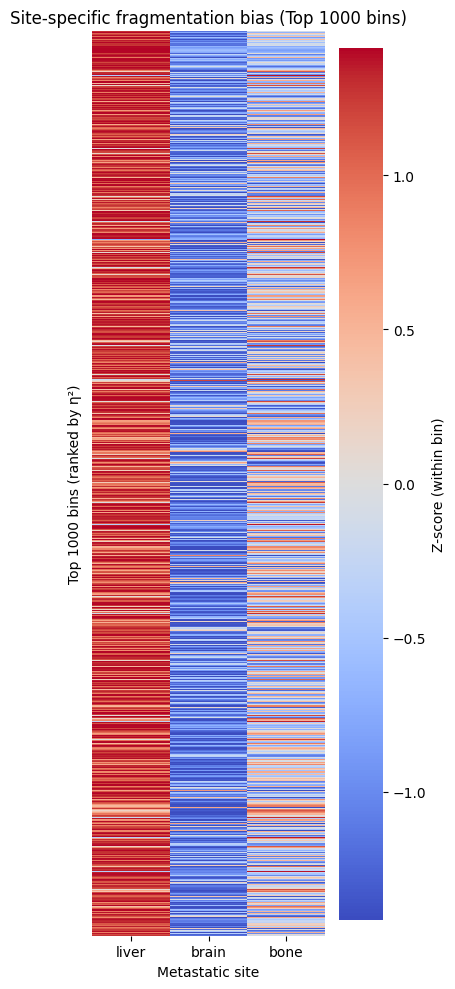

In [14]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# load final annotated file
df = pd.read_csv(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe50.top1000.with_site_direction.tsv",
    sep="\t"
)

# keep bins ordered by effect size
df = df.sort_values("rank_eta2")

# site-wise median matrix
mat = df[["median_liver", "median_brain", "median_bone"]].values

# Z-score across sites per bin
mat_z = (mat - mat.mean(axis=1, keepdims=True)) / mat.std(axis=1, keepdims=True)

mat_z = pd.DataFrame(
    mat_z,
    index=df["bin_id"],
    columns=["liver", "brain", "bone"]
)

# plot heatmap
plt.figure(figsize=(4, 10))
sns.heatmap(
    mat_z,
    cmap="coolwarm",
    center=0,
    yticklabels=False,
    cbar_kws={"label": "Z-score (within bin)"}
)
plt.xlabel("Metastatic site")
plt.ylabel("Top 1000 bins (ranked by η²)")
plt.title("Site-specific fragmentation bias (Top 1000 bins)")
plt.tight_layout()
plt.show()


Bins after raw KW p<0.05 filter: 519


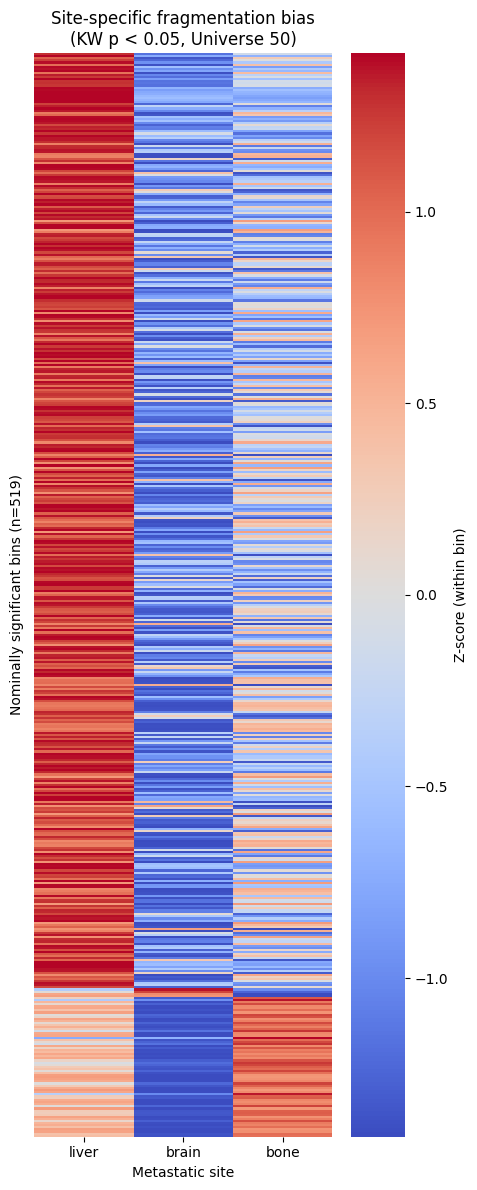

Saved heatmap:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/heatmap.universe50.top1000.site_grouped_rawKWp.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/heatmap.universe50.top1000.site_grouped_rawKWp.pdf


In [19]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# -------------------------
# Paths
# -------------------------
INFILE = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/"
    "Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/"
    "Effect_size/KW_BH/KW_BH.universe50.top1000.with_site_direction.tsv"
)

OUTDIR = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/"
    "Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/"
    "Effect_size/KW_BH"
)

os.makedirs(OUTDIR, exist_ok=True)

OUTPNG = os.path.join(OUTDIR, "heatmap.universe50.top1000.site_grouped_rawKWp.png")
OUTPDF = os.path.join(OUTDIR, "heatmap.universe50.top1000.site_grouped_rawKWp.pdf")

# -------------------------
# Load data
# -------------------------
df = pd.read_csv(INFILE, sep="\t")

# Keep bins with nominal KW significance
df = df[df["kw_p"] < 0.05].copy()

print("Bins after raw KW p<0.05 filter:", df.shape[0])

# -------------------------
# Order bins within site groups
# -------------------------
site_order = ["liver", "brain", "bone"]
df["site_highest"] = pd.Categorical(df["site_highest"], categories=site_order, ordered=True)

# sort by site group, then effect size rank
df = df.sort_values(["site_highest", "rank_eta2"])

# -------------------------
# Build median matrix
# -------------------------
mat = df[["median_liver", "median_brain", "median_bone"]].to_numpy(dtype=float)

# Row-wise z-score
row_means = mat.mean(axis=1, keepdims=True)
row_stds  = mat.std(axis=1, keepdims=True)

# avoid division by zero
row_stds[row_stds == 0] = 1

mat_z = (mat - row_means) / row_stds

mat_z = pd.DataFrame(
    mat_z,
    index=df["bin_id"],
    columns=["liver", "brain", "bone"]
)

# -------------------------
# Plot heatmap
# -------------------------
plt.figure(figsize=(4.8, 12))

sns.heatmap(
    mat_z,
    cmap="coolwarm",
    center=0,
    yticklabels=False,
    xticklabels=True,
    cbar_kws={"label": "Z-score (within bin)"}
)

plt.xlabel("Metastatic site")
plt.ylabel(f"Nominally significant bins (n={df.shape[0]})")
plt.title("Site-specific fragmentation bias\n(KW p < 0.05, Universe 50)")

plt.tight_layout()

# Save
plt.savefig(OUTPNG, dpi=300, bbox_inches="tight")
plt.savefig(OUTPDF, bbox_inches="tight")
plt.show()
plt.close()

print("Saved heatmap:")
print(OUTPNG)
print(OUTPDF)

In [20]:
import pandas as pd
import numpy as np

BINS_TSV = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe50.top1000.with_site_direction.tsv"

CYTOBAND = "/ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/Human_ref_hg38_p7/cytoBand.txt"

OUT_TSV = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe50.rawKWp_sig.with_site_direction.with_chrarm.tsv"

# -------------------------
# Load bins + nominal KW filter
# -------------------------
df = pd.read_csv(BINS_TSV, sep="\t", dtype={"bin_id": str})
df_sig = df[df["kw_p"] < 0.05].copy()
print("Total nominally significant bins (raw KW p < 0.05):", df_sig.shape[0])

# Parse bin_id: chr3_171800000_171900000
parts = df_sig["bin_id"].astype(str).str.split("_", expand=True)
df_sig["chrom"] = parts.iloc[:, 0].astype(str).str.strip()
df_sig["start"] = parts.iloc[:, 1].astype(int)
df_sig["end"]   = parts.iloc[:, 2].astype(int)
df_sig["mid"]   = ((df_sig["start"] + df_sig["end"]) // 2).astype(int)

# -------------------------
# Load cytoband
# -------------------------
cyto = pd.read_csv(
    CYTOBAND,
    sep="\t",
    header=None,
    names=["chrom", "start", "end", "band", "stain"]
)
cyto["chrom"] = cyto["chrom"].astype(str).str.strip()
cyto["arm"] = cyto["band"].astype(str).str[0]
cyto = cyto[cyto["arm"].isin(["p", "q"])].copy()

# Pre-split cytoband dict by chromosome
cyto_by_chr = {
    c: d.sort_values("start").reset_index(drop=True)
    for c, d in cyto.groupby("chrom")
}

# -------------------------
# Chromosome-wise merge_asof
# -------------------------
out_chunks = []

for chrom, sub in df_sig.groupby("chrom", sort=False):
    sub = sub.sort_values("mid").reset_index(drop=True)

    cb = cyto_by_chr.get(chrom)
    if cb is None or cb.shape[0] == 0:
        sub["arm"] = np.nan
        sub["band"] = np.nan
        sub["chrom_arm"] = np.nan
        out_chunks.append(sub)
        continue

    cb2 = cb[["start", "end", "arm", "band"]].rename(
        columns={"start": "cb_start", "end": "cb_end"}
    ).copy()
    cb2 = cb2.sort_values("cb_start").reset_index(drop=True)

    annot = pd.merge_asof(
        sub,
        cb2,
        left_on="mid",
        right_on="cb_start",
        direction="backward",
        allow_exact_matches=True
    )

    # verify midpoint lies within cytoband interval
    in_interval = (annot["mid"] >= annot["cb_start"]) & (annot["mid"] < annot["cb_end"])
    annot.loc[~in_interval, ["arm", "band"]] = np.nan

    annot["chrom_arm"] = np.where(
        annot["arm"].isna(),
        np.nan,
        annot["chrom"] + annot["arm"].astype(str)
    )

    out_chunks.append(annot)

annot_all = pd.concat(out_chunks, ignore_index=True)

# Optional: drop helper columns
# annot_all.drop(columns=["mid", "cb_start", "cb_end"], inplace=True, errors="ignore")

annot_all.to_csv(OUT_TSV, sep="\t", index=False)
print("Wrote:", OUT_TSV)

print("chrom_arm counts (top):")
print(annot_all["chrom_arm"].value_counts(dropna=False).head(20))

Total nominally significant bins (raw KW p < 0.05): 519
Wrote: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe50.rawKWp_sig.with_site_direction.with_chrarm.tsv
chrom_arm counts (top):
chr2q     36
chr4q     32
chr5q     31
chr12q    26
chr14q    25
chr7q     25
chr11q    24
chr3p     21
chr6q     21
chr18q    20
chr6p     19
chr10q    17
chr1p     17
chr9q     17
chr13q    16
chr11p    15
chr3q     15
chr17q    14
chr15q    14
chr21q    13
Name: chrom_arm, dtype: int64


In [23]:
# Step 9A: Make a BED for the nominally significant bins (raw KW p < 0.05)
import pandas as pd

INFILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe50.top1000.with_site_direction.tsv"

OUT_BED = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/universe50.rawKWp_sig.bins519.bed"

df = pd.read_csv(INFILE, sep="\t", dtype={"bin_id": str})
df = df[df["kw_p"] < 0.05].copy()

parts = df["bin_id"].str.split("_", expand=True)
df["chr"] = parts.iloc[:, 0]
df["start"] = parts.iloc[:, 1].astype(int)
df["end"] = parts.iloc[:, 2].astype(int)

# 4th column = bin_id (so we can map back later)
bed = df[["chr", "start", "end", "bin_id"]].drop_duplicates()
bed.to_csv(OUT_BED, sep="\t", header=False, index=False)

print("Wrote:", OUT_BED, "n =", bed.shape[0])

# B) Intersect bins with genes (By using Bedtool)
# C) Collapse genes per bin_id + merge back into your TSV
import pandas as pd

IN_TSV = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe50.top1000.with_site_direction.tsv"

HITS = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_sampleNorm/KW_BH/universe50.BHsig.bins.geneHits.tsv"

OUT_TSV = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe50.rawKWp_sig.with_site_direction.with_genes.tsv"

# Keep nominally significant bins only
df = pd.read_csv(IN_TSV, sep="\t", dtype={"bin_id": str})
df_sig = df[df["kw_p"] < 0.05].copy()

# Read bedtools intersect output (no header)
hits = pd.read_csv(HITS, sep="\t", header=None)

# bedtools intersect -wa -wb output columns:
# a: chr, start, end, bin_id
# b: chr, start, end, gene_name, ensg   (assuming gencode.v19.genes.bed has 5 columns)
BIN_ID_COL = 3
GENE_NAME_COL = 7   # adjust only if your gene BED has a different structure

hits = hits[[BIN_ID_COL, GENE_NAME_COL]].rename(
    columns={BIN_ID_COL: "bin_id", GENE_NAME_COL: "gene_name"}
)

hits["gene_name"] = hits["gene_name"].astype(str).str.strip()

# Collapse unique gene names per bin
gene_map = (
    hits.groupby("bin_id")["gene_name"]
        .apply(lambda x: ",".join(sorted(set(g for g in x if g not in ["", "nan", "None"]))))
        .reset_index()
        .rename(columns={"gene_name": "genes"})
)

# Merge back into filtered table
df_sig = df_sig.merge(gene_map, on="bin_id", how="left")
df_sig["genes"] = df_sig["genes"].fillna("")

df_sig.to_csv(OUT_TSV, sep="\t", index=False)
print("Wrote:", OUT_TSV)
print("Nominally significant bins with gene annotations:", df_sig.shape[0])

Wrote: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/universe50.rawKWp_sig.bins519.bed n = 519
Wrote: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe50.rawKWp_sig.with_site_direction.with_genes.tsv
Nominally significant bins with gene annotations: 519


In [24]:
# Generate per-site BED files for LOLA from nominally significant bins
import os
import pandas as pd

# -------------------------
# INPUT
# -------------------------
INFILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe50.top1000.with_site_direction.tsv"

# -------------------------
# OUTPUT DIR
# -------------------------
OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH"
os.makedirs(OUTDIR, exist_ok=True)

UNIVERSE_PCT = 50
SITES = ["liver", "brain", "bone"]

# -------------------------
# Convert bin_id like chr3_171800000_171900000 -> BED
# -------------------------
def bin_id_to_bed(df, bin_col="bin_id"):
    parts = df[bin_col].str.split("_", expand=True)
    out = pd.DataFrame({
        "chr": parts[0],
        "start": parts[1].astype(int),
        "end": parts[2].astype(int),
    })
    return out

# -------------------------
# Load and filter
# -------------------------
df = pd.read_csv(INFILE, sep="\t", dtype={"bin_id": str})

# Keep nominally significant bins only
df = df[df["kw_p"] < 0.05].copy()
print("Total nominally significant bins (raw KW p < 0.05):", df.shape[0])

# -------------------------
# Write per-site BEDs
# -------------------------
for site in SITES:
    sub = df[df["site_highest"] == site].copy()

    # optional: remove duplicate bins if any
    sub = sub.drop_duplicates(subset=["bin_id"])

    bed = bin_id_to_bed(sub)

    out_bed = os.path.join(
        OUTDIR,
        f"universe{UNIVERSE_PCT}.rawKWp_sig.{site}_high.bed"
    )
    bed.to_csv(out_bed, sep="\t", header=False, index=False)

    print(f"Wrote {site}_high: {out_bed}  (n={bed.shape[0]})")

Total nominally significant bins (raw KW p < 0.05): 519
Wrote liver_high: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/universe50.rawKWp_sig.liver_high.bed  (n=448)
Wrote brain_high: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/universe50.rawKWp_sig.brain_high.bed  (n=4)
Wrote bone_high: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/universe50.rawKWp_sig.bone_high.bed  (n=67)


In [25]:
# Generate bed file for LOLA by using nominally significant bins
import os
import pandas as pd

INFILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe50.top1000.with_site_direction.tsv"

OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH"
os.makedirs(OUTDIR, exist_ok=True)

UNIVERSE_PCT = 50
SITES = ["liver", "brain", "bone"]

def bin_id_to_bed(df, bin_col="bin_id"):
    # handle empty input
    if df.shape[0] == 0:
        return pd.DataFrame(columns=["chr", "start", "end"])

    parts = df[bin_col].astype(str).str.split("_", expand=True)

    # If split didn't produce 3 columns, return empty
    if parts.shape[1] < 3:
        return pd.DataFrame(columns=["chr", "start", "end"])

    out = pd.DataFrame({
        "chr": parts.iloc[:, 0],
        "start": pd.to_numeric(parts.iloc[:, 1], errors="coerce"),
        "end": pd.to_numeric(parts.iloc[:, 2], errors="coerce"),
    }).dropna(subset=["chr", "start", "end"]).copy()

    out["start"] = out["start"].astype(int)
    out["end"] = out["end"].astype(int)
    return out

# -------------------------
# Load
# -------------------------
df = pd.read_csv(INFILE, sep="\t", dtype={"bin_id": str})

# Normalize site_highest labels to avoid mismatch
df["site_highest_norm"] = df["site_highest"].astype(str).str.strip().str.lower()

# Nominally significant only
df_sig = df[df["kw_p"] < 0.05].copy()
print("Total nominally significant bins (raw KW p < 0.05):", df_sig.shape[0])

# quick check: what site labels exist after filtering
print("site_highest counts (raw KW p < 0.05):")
print(df_sig["site_highest_norm"].value_counts(dropna=False))

# -------------------------
# Write per-site BEDs
# -------------------------
for site in SITES:
    sub = df_sig[df_sig["site_highest_norm"] == site].copy()

    if sub.shape[0] == 0:
        print(f"SKIP {site}: no nominally significant bins")
        continue

    sub = sub.drop_duplicates(subset=["bin_id"])
    bed = bin_id_to_bed(sub)

    if bed.shape[0] == 0:
        print(f"SKIP {site}: bin_id parsing produced 0 BED rows (check bin_id format)")
        continue

    out_bed = os.path.join(OUTDIR, f"universe{UNIVERSE_PCT}.rawKWp_sig.{site}_high.bed")
    bed.to_csv(out_bed, sep="\t", header=False, index=False)

    print(f"Wrote {site}_high: {out_bed}  (n={bed.shape[0]})")

Total nominally significant bins (raw KW p < 0.05): 519
site_highest counts (raw KW p < 0.05):
liver    448
bone      67
brain      4
Name: site_highest_norm, dtype: int64
Wrote liver_high: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/universe50.rawKWp_sig.liver_high.bed  (n=448)
Wrote brain_high: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/universe50.rawKWp_sig.brain_high.bed  (n=4)
Wrote bone_high: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/universe50.rawKWp_sig.bone_high.bed  (n=67)


Nominally significant bins (raw KW p < 0.05): 519
Nominally significant bins found in ratio matrix (autosomes): 519
Using TOP3 sites only: ['liver', 'bone', 'brain']
Samples with meta: 50
Nominally significant bins with arm assigned: 519


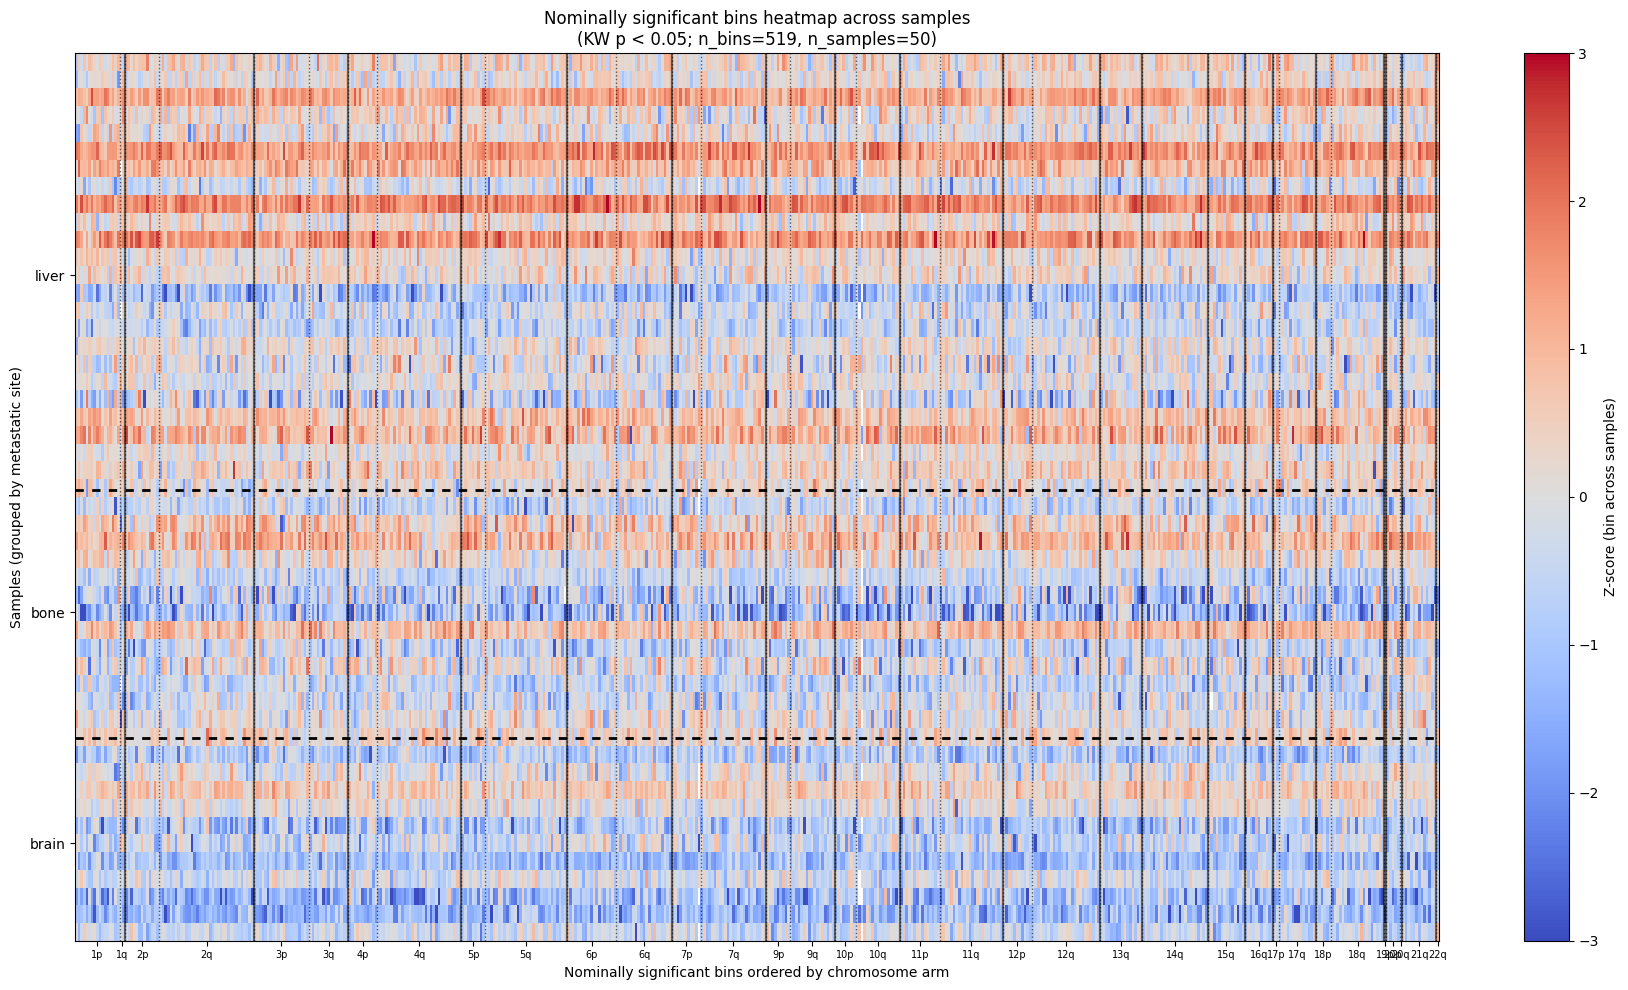

Saved:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/rawKWp_sig_bins_allSamples_armOrdered_heatmap/heatmap.rawKWp_sig.allSamples.chrArmOrdered.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/rawKWp_sig_bins_allSamples_armOrdered_heatmap/heatmap.rawKWp_sig.allSamples.chrArmOrdered.pdf


In [29]:
# Heatmap: nominally significant bins (raw KW p < 0.05) across ALL samples
# X-axis: chr + arm (p/q) ordered; Y-axis: samples grouped by metastatic site

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Inputs
# -----------------------------
RATIO_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"

BINS_TSV = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe50.top1000.with_site_direction.tsv"

META_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_one_per_bios_site.csv"

CYTOBAND = "/ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/Human_ref_hg38_p7/cytoBand.txt"

OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/rawKWp_sig_bins_allSamples_armOrdered_heatmap"
os.makedirs(OUTDIR, exist_ok=True)

OUTPNG = os.path.join(OUTDIR, "heatmap.rawKWp_sig.allSamples.chrArmOrdered.png")
OUTPDF = os.path.join(OUTDIR, "heatmap.rawKWp_sig.allSamples.chrArmOrdered.pdf")

# -----------------------------
# Options
# -----------------------------
LOG2_TRANSFORM = True
Z_SCORE_PER_BIN = True
CLIP_VMIN, CLIP_VMAX = (-3, 3)
FIGSIZE = (18, 10)

# If you ONLY want top 3 sites
TOP3_ONLY = True

# -----------------------------
# Helpers
# -----------------------------
CHR_ORDER = [f"chr{i}" for i in range(1, 23)]

def parse_bin(bin_id: str):
    chrom, start, end = bin_id.split("_")
    return chrom, int(start), int(end)

def load_cytoband(cyto_path):
    cb = pd.read_csv(
        cyto_path, sep="\t", header=None,
        names=["chrom", "start", "end", "band", "stain"],
        dtype={"chrom": str, "start": int, "end": int, "band": str, "stain": str}
    )
    cb = cb[cb["chrom"].isin(CHR_ORDER)].copy()
    cb["arm"] = cb["band"].str[0]
    return cb

def assign_arm_to_bin(bin_id, cytoband_df):
    chrom, start, end = parse_bin(bin_id)
    if chrom not in CHR_ORDER:
        return None
    mid = (start + end) // 2
    hits = cytoband_df[
        (cytoband_df["chrom"] == chrom) &
        (cytoband_df["start"] <= mid) &
        (cytoband_df["end"] >= mid)
    ]
    if hits.shape[0] == 0:
        return None
    arm = hits.iloc[0]["arm"]
    if arm not in ("p", "q"):
        return None
    return arm

def zscore_by_bin_across_samples(df):
    mu = df.mean(axis=0, skipna=True)
    sd = df.std(axis=0, skipna=True).replace(0, np.nan)
    return (df - mu) / sd

def compute_site_order(meta_series):
    return meta_series.value_counts().index.tolist()

# -----------------------------
# Load ratio matrix
# -----------------------------
ratio = pd.read_csv(RATIO_FILE)
ratio = ratio.set_index("Unnamed: 0")
ratio.index.name = "sample"

if LOG2_TRANSFORM:
    ratio = np.log2(ratio.replace(0, np.nan))

# -----------------------------
# Load nominally significant bins list
# -----------------------------
df = pd.read_csv(BINS_TSV, sep="\t")
df = df[df["kw_p"] < 0.05].copy()
print("Nominally significant bins (raw KW p < 0.05):", df.shape[0])

sig_bins = df["bin_id"].astype(str).tolist()

# Keep only bins present in ratio columns + autosomes
sig_bins = [b for b in sig_bins if b in ratio.columns and b.split("_")[0] in CHR_ORDER]
print("Nominally significant bins found in ratio matrix (autosomes):", len(sig_bins))

# -----------------------------
# Load meta + match samples
# -----------------------------
meta = pd.read_csv(META_FILE)
meta["id"] = meta["id"].astype(str)
meta["metastatic_sites"] = meta["metastatic_sites"].astype(str).str.lower().str.strip()

# Keep only samples present in ratio
meta = meta[meta["id"].isin(ratio.index)].copy()
meta = meta.set_index("id")

if TOP3_ONLY:
    top3 = meta["metastatic_sites"].value_counts().head(3).index.tolist()
    meta = meta[meta["metastatic_sites"].isin(top3)].copy()
    print("Using TOP3 sites only:", top3)

# Subset ratio to samples with meta
ratio2 = ratio.loc[meta.index].copy()
print("Samples with meta:", ratio2.shape[0])

# -----------------------------
# Cytoband: assign chr arm to each bin
# -----------------------------
cyto = load_cytoband(CYTOBAND)

bin_rows = []
for b in sig_bins:
    chrom, start, end = parse_bin(b)
    arm = assign_arm_to_bin(b, cyto)
    if arm is None:
        continue
    chrom_num = int(chrom.replace("chr", ""))
    bin_rows.append((b, chrom, chrom_num, arm, start, end))

bin_annot = pd.DataFrame(
    bin_rows,
    columns=["bin_id", "chrom", "chrom_num", "arm", "start", "end"]
)
print("Nominally significant bins with arm assigned:", bin_annot.shape[0])

# Order bins by chr -> arm (p then q) -> start
arm_order = {"p": 0, "q": 1}
bin_annot["arm_rank"] = bin_annot["arm"].map(arm_order).astype(int)
bin_annot = bin_annot.sort_values(["chrom_num", "arm_rank", "start"]).reset_index(drop=True)

ordered_bins = bin_annot["bin_id"].tolist()

# -----------------------------
# Build heatmap matrix
# -----------------------------
X = ratio2[ordered_bins].copy()

if Z_SCORE_PER_BIN:
    X = zscore_by_bin_across_samples(X)

# -----------------------------
# Order samples by metastatic site
# -----------------------------
site_order = compute_site_order(meta["metastatic_sites"])
meta_ord = meta.copy()
meta_ord["metastatic_sites"] = pd.Categorical(
    meta_ord["metastatic_sites"],
    categories=site_order,
    ordered=True
)
meta_ord = meta_ord.sort_values(["metastatic_sites"])

X = X.loc[meta_ord.index]

# Y boundaries between site blocks
site_sizes = (
    meta_ord["metastatic_sites"]
    .value_counts()
    .reindex(site_order)
    .fillna(0)
    .astype(int)
)
y_boundaries = np.cumsum(site_sizes.values)[:-1]

# Y tick labels at site midpoints
yticks, ylabels = [], []
start = 0
for site in site_order:
    n = int((meta_ord["metastatic_sites"] == site).sum())
    if n > 0:
        yticks.append(start + n / 2)
        ylabels.append(site)
        start += n

# -----------------------------
# X boundaries: arm changes + chr changes
# -----------------------------
arm_keys = list(zip(bin_annot["chrom"].tolist(), bin_annot["arm"].tolist()))
x_boundaries = []
chr_boundaries = []

if len(arm_keys) > 0:
    prev = arm_keys[0]
    prev_chr = bin_annot.loc[0, "chrom"]

    for i in range(1, len(arm_keys)):
        if arm_keys[i] != prev:
            x_boundaries.append(i - 0.5)
            prev = arm_keys[i]
        if bin_annot.loc[i, "chrom"] != prev_chr:
            chr_boundaries.append(i - 0.5)
            prev_chr = bin_annot.loc[i, "chrom"]

# X tick labels: one per chr-arm block midpoint
blocks = []
if len(arm_keys) > 0:
    block_start = 0
    for i in range(1, len(arm_keys) + 1):
        if i == len(arm_keys) or arm_keys[i] != arm_keys[i - 1]:
            chrom, arm = arm_keys[i - 1]
            blocks.append((chrom, arm, block_start, i - 1))
            block_start = i

xticks = [(s + e) / 2 for (_, _, s, e) in blocks]
xlabels = [f"{c.replace('chr','')}{a}" for (c, a, _, _) in blocks]

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=FIGSIZE)
plt.imshow(
    X.values,
    aspect="auto",
    interpolation="nearest",
    cmap="coolwarm",
    vmin=CLIP_VMIN,
    vmax=CLIP_VMAX
)

cbar_label = "Z-score (bin across samples)" if Z_SCORE_PER_BIN else ("log2(short/long)" if LOG2_TRANSFORM else "short/long")
plt.colorbar(label=cbar_label)

# Horizontal separators between metastatic site blocks
for b in y_boundaries:
    plt.axhline(b + 0.1, color="black", linewidth=2.0, linestyle=(0, (3, 3)))

# Vertical separators between chromosome arms
for xb in x_boundaries:
    plt.axvline(xb, color="black", linewidth=1.0, linestyle=":", alpha=0.6)

# Thicker separators between chromosomes
for xb in chr_boundaries:
    plt.axvline(xb, color="black", linewidth=1.6, linestyle="-", alpha=0.55)

plt.yticks(yticks, ylabels)
plt.xticks(xticks, xlabels, fontsize=7, rotation=0)

plt.xlabel("Nominally significant bins ordered by chromosome arm")
plt.ylabel("Samples (grouped by metastatic site)")
plt.title(
    f"Nominally significant bins heatmap across samples\n"
    f"(KW p < 0.05; n_bins={X.shape[1]}, n_samples={X.shape[0]})"
)

plt.tight_layout()
plt.savefig(OUTPNG, dpi=300)
plt.savefig(OUTPDF)
plt.show()
plt.close()

print("Saved:")
print(OUTPNG)
print(OUTPDF)